In [ ]:
# ============================================
# 🔧 SETUP ENVIRONMENT
# ============================================

# Install necessary libraries
!pip install segment-anything timm einops torchvision tqdm opencv-python scikit-image

import os, torch

# Device check
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("💻 Device:", device)


  Using cached timm-1.0.22-py3-none-any.whl.metadata (63 kB)
  Using cached einops-0.8.1-py3-none-any.whl.metadata (13 kB)
  Using cached shellingham-1.5.4-py2.py3-none-any.whl.metadata (3.5 kB)
Using cached timm-1.0.22-py3-none-any.whl (2.5 MB)
Using cached einops-0.8.1-py3-none-any.whl (64 kB)
   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   ---------------------------------------- 2.9/2.9 MB 24.3 MB/s  0:00:00
Using cached shellingham-1.5.4-py2.py3-none-any.whl (9.8 kB)

   ----- ----------------------------------  2/14 [idna]
   ----------- ----------------------------  4/14 [h11]
   -------------- -------------------------  5/14 [einops]
   -------------- -------------------------  5/14 [einops]
   ----------------- ----------------------  6/14 [click]
   ---------------------- -----------------  8/14 [typer-slim]
   ------------------------- --------------  9/14 [httpcore]
   ---------------------------- ----------- 10/14 [anyio]
   ------------------------

In [ ]:
# ============================================
# 📂 PATHS — Update only if your folder names differ
# ============================================

# Use the dataset path from your local machine
DATASET_BASE = r"C:\Users\User\Desktop\Btech_asmita\archive"

IMG_TRAIN = f"{DATASET_BASE}/images/train"
MASK_TRAIN = f"{DATASET_BASE}/masks/train"
IMG_VAL   = f"{DATASET_BASE}/images/val"
MASK_VAL  = f"{DATASET_BASE}/masks/val"

SAVE_DIR = r"C:\Users\User\Desktop\Btech_asmita\unet_project\sam_unet_runs"
os.makedirs(SAVE_DIR, exist_ok=True)

# Auto-create if missing (safe)
for p in [IMG_TRAIN, MASK_TRAIN, IMG_VAL, MASK_VAL]:
    if not os.path.exists(p):
        os.makedirs(p, exist_ok=True)
    print("📁 Folder:", p, "| Exists:", os.path.exists(p))


📁 Folder: C:\Users\User\Desktop\Btech_asmita\archive/images/train | Exists: True
📁 Folder: C:\Users\User\Desktop\Btech_asmita\archive/masks/train | Exists: True
📁 Folder: C:\Users\User\Desktop\Btech_asmita\archive/images/val | Exists: True
📁 Folder: C:\Users\User\Desktop\Btech_asmita\archive/masks/val | Exists: True


In [ ]:
# ============================================
# 🧠 LOAD SAM CHECKPOINT
# ============================================

SAM_CKPT = r"C:\Users\User\Desktop\Btech_asmita\unet_project\sam_vit_b.pth"

# Check if the checkpoint exists, otherwise download it
if not os.path.exists(SAM_CKPT):
    print("⏳ Downloading SAM checkpoint...")
    import urllib.request
    url = "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth"
    urllib.request.urlretrieve(url, SAM_CKPT)

print("✅ SAM checkpoint ready:", os.path.exists(SAM_CKPT))


⏳ Downloading SAM checkpoint...
✅ SAM checkpoint ready: True


In [ ]:
import os

# Set the dataset base path for your local machine
DATASET_BASE = r"C:\Users\User\Desktop\Btech_asmita\archive"

# Example of how you could directly reference files
# Replace this with the actual path to your dataset files
IMG_TRAIN = os.path.join(DATASET_BASE, 'images/train')
MASK_TRAIN = os.path.join(DATASET_BASE, 'masks/train')

print("📂 Dataset paths set:", IMG_TRAIN, MASK_TRAIN)


📂 Dataset paths set: C:\Users\User\Desktop\Btech_asmita\archive\images/train C:\Users\User\Desktop\Btech_asmita\archive\masks/train


In [ ]:
import os
import zipfile

# List files in the current directory
for file in os.listdir():
    if file.endswith(".zip"):
        zip_path = file
        print("Found ZIP:", zip_path)

        # Define the extraction path on your local machine
        extract_path = r"C:\Users\User\Desktop\Btech_asmita\unet_project\extracted"
        os.makedirs(extract_path, exist_ok=True)

        # Extract the contents of the ZIP file
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_path)

        print("📦 Extraction Complete at", extract_path)


Found ZIP: archive.zip
📦 Extraction Complete at C:\Users\User\Desktop\Btech_asmita\unet_project\extracted


In [ ]:
import os

os.listdir(r"C:\Users\User\Desktop\Btech_asmita\unet_project")


['extracted', 'sam_unet_runs', 'sam_vit_b.pth']

In [ ]:
import shutil
import os

# Local extracted dataset folder (previous extraction step)
extract_local = r"C:\Users\User\Desktop\Btech_asmita\unet_project\extracted"

# Target dataset path on your local PC
drive_target = r"C:\Users\User\Desktop\Btech_asmita\unet_project\dataset_zip"

# Create target folder if not exists
os.makedirs(drive_target, exist_ok=True)

# Copy files from extracted dataset to target folder
for root, dirs, files in os.walk(extract_local):
    for file in files:
        src = os.path.join(root, file)
        dst = os.path.join(drive_target, os.path.relpath(src, extract_local))
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        shutil.copy2(src, dst)

print("✅ Dataset copied successfully to:", drive_target)


✅ Dataset copied successfully to: C:\Users\User\Desktop\Btech_asmita\unet_project\dataset_zip


In [ ]:
import os

# FIXED LOCAL DATASET PATH
dataset = r"C:\Users\User\Desktop\Btech_asmita\unet_project\dataset_zip"

img_ext = (".png", ".jpg", ".jpeg")
mask_ext = (".png", ".jpg", ".jpeg", ".tif", ".tiff")

images = []
masks = []

for root, dirs, files in os.walk(dataset):
    for f in files:
        f_lower = f.lower()
        if f_lower.endswith(img_ext):
            images.append(os.path.join(root, f))
        if f_lower.endswith(mask_ext):
            masks.append(os.path.join(root, f))

print("🖼 Images found:", len(images))
print("🎭 Masks found:", len(masks))


🖼 Images found: 540
🎭 Masks found: 840


In [ ]:
import os

for root, dirs, files in os.walk(r"C:\Users\User\Desktop\Btech_asmita\unet_project", topdown=True):
    for d in dirs:
        if "tissue" in d.lower():
            print("📂 Found folder:", os.path.join(root, d))


📂 Found folder: C:\Users\User\Desktop\Btech_asmita\unet_project\dataset_zip\tissue images
📂 Found folder: C:\Users\User\Desktop\Btech_asmita\unet_project\extracted\tissue images


In [ ]:
import os, shutil

# ============================================
# 📂 CORRECT PATHS (local Jupyter)
# ============================================
DATASET_BASE = r"C:\Users\User\Desktop\Btech_asmita\unet_project\dataset_zip"
IMG_DIR = os.path.join(DATASET_BASE, "tissue images")
MASK_DIR = os.path.join(DATASET_BASE, "Annotator 1 (biologist)", "mask binary")

print("📌 Image directory :", IMG_DIR)
print("📌 Mask directory  :", MASK_DIR)

# ============================================
# 🧩 SPLIT DATA
# ============================================
all_imgs = sorted([f for f in os.listdir(IMG_DIR) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.tif'))])
split_idx = int(0.8 * len(all_imgs))
train_imgs = all_imgs[:split_idx]
val_imgs   = all_imgs[split_idx:]

IMG_TRAIN  = os.path.join(DATASET_BASE, "images", "train")
IMG_VAL    = os.path.join(DATASET_BASE, "images", "val")
MASK_TRAIN = os.path.join(DATASET_BASE, "masks", "train")
MASK_VAL   = os.path.join(DATASET_BASE, "masks", "val")

for p in [IMG_TRAIN, IMG_VAL, MASK_TRAIN, MASK_VAL]:
    os.makedirs(p, exist_ok=True)

# ============================================
# ⚙️ MASK SEARCH (SMART)
# ============================================
def find_mask(img_name):
    base = os.path.splitext(img_name)[0]
    possible_masks = [
        f"{base}.png", f"{base}.tif",
        f"{base} (1).png", f"{base} (1).tif"
    ]
    for fname in os.listdir(MASK_DIR):
        if fname in possible_masks:
            return os.path.join(MASK_DIR, fname)
    return None

# ============================================
# 📦 COPY TRAIN & VAL
# ============================================
missing = []

def copy_split(img_list, img_out, mask_out):
    for img in img_list:
        shutil.copy(os.path.join(IMG_DIR, img), os.path.join(img_out, img))
        mask_path = find_mask(img)
        if mask_path:
            shutil.copy(mask_path, os.path.join(mask_out, os.path.basename(mask_path)))
        else:
            missing.append(img)

print(f"🔁 Copying dataset ({len(train_imgs)} train, {len(val_imgs)} val)...")
copy_split(train_imgs, IMG_TRAIN, MASK_TRAIN)
copy_split(val_imgs, IMG_VAL, MASK_VAL)

# ============================================
# 📝 REPORT
# ============================================
if missing:
    print(f"⚠️ Missing masks for {len(missing)} images. Writing report...")
    with open(os.path.join(DATASET_BASE, "missing_mask_list.txt"), "w") as f:
        for m in missing:
            f.write(m + "\n")
            print("  -", m)
else:
    print("🎉 All masks found!")

print("✅ Train/Val split complete.")


📌 Image directory : C:\Users\User\Desktop\Btech_asmita\unet_project\dataset_zip\tissue images
📌 Mask directory  : C:\Users\User\Desktop\Btech_asmita\unet_project\dataset_zip\Annotator 1 (biologist)\mask binary
🔁 Copying dataset (24 train, 6 val)...
🎉 All masks found!
✅ Train/Val split complete.


In [ ]:
import os
import urllib.request

# ============================================
# 🧠 LOAD SAM CHECKPOINT
# ============================================

SAM_CKPT = r"C:\Users\User\Desktop\Btech_asmita\unet_project\sam_vit_b.pth"

if not os.path.exists(SAM_CKPT):
    print("⬇️ Downloading SAM ViT-B checkpoint...")
    url = "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth"
    urllib.request.urlretrieve(url, SAM_CKPT)

print("✅ SAM checkpoint ready:", SAM_CKPT)


✅ SAM checkpoint ready: C:\Users\User\Desktop\Btech_asmita\unet_project\sam_vit_b.pth


In [ ]:
# ============================================
# 🧠 LOAD SAM ENCODER (ViT-B) — FINAL WORKING VERSION
# ============================================

# 1) Install SAM if missing (works in Jupyter too)
!pip install -q git+https://github.com/facebookresearch/segment-anything.git

# 2) Imports
import os, torch
import numpy as np
from segment_anything import sam_model_registry
from segment_anything.utils.transforms import ResizeLongestSide
import torch.nn.functional as F
import urllib.request

# 3) Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("💻 Using device:", device)

# 4) Load checkpoint
SAM_CKPT = r"C:\Users\User\Desktop\Btech_asmita\unet_project\sam_vit_b.pth"

if not os.path.exists(SAM_CKPT):
    print("⏳ Downloading SAM checkpoint...")
    url = "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth"
    urllib.request.urlretrieve(url, SAM_CKPT)

print("🔑 SAM checkpoint ready:", SAM_CKPT)

# 5) Load SAM model
sam = sam_model_registry["vit_b"](checkpoint=SAM_CKPT).to(device)
sam.eval()
for p in sam.parameters():
    p.requires_grad = False

sam_pre = ResizeLongestSide(sam.image_encoder.img_size)

# 6) Embedding function
@torch.no_grad()
def sam_embedding_from_rgb(batch_rgb):
    """
    Convert batch of normalized tensors [B,3,H,W] → SAM embeddings [B,256,32,32]
    """
    batch_np = []
    for img in batch_rgb:
        img_np = (img.detach().cpu().moveaxis(0, -1).numpy() * 255).astype(np.uint8)
        batch_np.append(sam_pre.apply_image(img_np))

    batch_np = np.stack(batch_np, axis=0)
    batch_t = torch.as_tensor(batch_np, device=device).permute(0, 3, 1, 2).float()

    embs = sam.image_encoder(batch_t)   # [B,256,H_e,W_e]
    embs = F.interpolate(embs, size=(32, 32), mode="bilinear", align_corners=False)
    return embs

print("🚀 SAM Encoder Ready: sam_embedding_from_rgb()")


💻 Using device: cuda
🔑 SAM checkpoint ready: C:\Users\User\Desktop\Btech_asmita\unet_project\sam_vit_b.pth


c:\Users\User\Desktop\Btech_asmita\.venv\lib\site-packages\segment_anything\build_sam.py:105: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(f)


🚀 SAM Encoder Ready: sam_embedding_from_rgb()


In [ ]:
# ============================================
# 🧱 MODEL: EUNet3+ + Multi-scale X-Gated Fusion with SAM
# ============================================
import torch
import torch.nn as nn
import torch.nn.functional as F

# ensure device is defined for Jupyter
device = 'cuda' if torch.cuda.is_available() else 'cpu'

class DoubleConv(nn.Module):
    """(Conv → BN → ReLU) × 2"""
    def __init__(self, in_c, out_c):
        super().__init__()
        self.seq = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.seq(x)


class UpBlock(nn.Module):
    """(Kept for compatibility, not used in EUNet3+)"""
    def __init__(self, in_c, out_c):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_c, out_c, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_c=out_c * 2, out_c=out_c)

    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[-1] != skip.shape[-1] or x.shape[-2] != skip.shape[-2]:
            diff_y = skip.size(-2) - x.size(-2)
            diff_x = skip.size(-1) - x.size(-1)
            x = F.pad(x, [diff_x // 2, diff_x - diff_x // 2,
                          diff_y // 2, diff_y - diff_y // 2])
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)


class XGatedFusion(nn.Module):
    """Enhanced X-Gated Fusion (same as before).
    Output has same channels as UNet feature (c_x).
    """
    def __init__(self, c_x, c_s):
        super().__init__()
        # project SAM channels → UNet channels
        self.proj_s = nn.Conv2d(c_s, c_x, kernel_size=1)
        self.proj_x = nn.Conv2d(c_x, c_x, kernel_size=1)

        # gates
        self.f_gate = nn.Conv2d(c_x, c_x, kernel_size=1)
        self.s_gate = nn.Conv2d(c_x, c_x, kernel_size=1)

        # multi-scale conv branch
        self.conv3 = nn.Conv2d(c_x, c_x, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(c_x, c_x, kernel_size=5, padding=2)

        # Squeeze-Excitation channel attention
        hidden = max(c_x // 4, 8)
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(c_x, hidden, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, c_x, kernel_size=1),
            nn.Sigmoid(),
        )

        self.out = nn.Conv2d(c_x, c_x, kernel_size=1)
        gn_groups = 8 if c_x >= 8 else 1
        self.gn = nn.GroupNorm(gn_groups, c_x)

    def forward(self, x_u, x_sam):
        # x_u: UNet feature [B, c_x, H, W]
        # x_sam: SAM feature [B, c_s, H, W] (already resized to same H,W)
        x_u = self.proj_x(x_u)
        x_sam = self.proj_s(x_sam)

        # cross-gating
        g_u = torch.sigmoid(self.f_gate(x_u))    # gate for SAM path
        g_s = torch.sigmoid(self.s_gate(x_sam))  # gate for UNet path

        u_g = x_u * g_s
        s_g = x_sam * g_u

        x = u_g + s_g

        # multi-scale conv (3×3 + 5×5)
        x_ms = self.conv3(x) + self.conv5(x)

        # SE channel attention
        w = self.se(x_ms)
        x_att = x_ms * w

        # residual + norm
        out = self.out(x_att)
        out = out + x   # residual
        out = self.gn(out)
        return out


class EUNet3PlusSAM(nn.Module):
    """
    EUNet3+-style full-scale decoder + multi-scale SAM fusion.
    Input : x [B,3,256,256], sam_emb [B,sam_c,32,32]
    Output: [B,1,256,256] (same as old UNetSAM)
    """
    def __init__(self, in_ch=3, out_ch=1, base_c=64, sam_c=256):
        super().__init__()
        # ------------ Encoder (same as before) ------------
        self.e1 = DoubleConv(in_ch, base_c)          # 64, 256×256
        self.e2 = DoubleConv(base_c, base_c * 2)     # 128, 128×128
        self.e3 = DoubleConv(base_c * 2, base_c * 4) # 256, 64×64
        self.e4 = DoubleConv(base_c * 4, base_c * 8) # 512, 32×32
        self.pool = nn.MaxPool2d(2)

        # ------------ Multi-scale SAM fusion (same channels as encoder) ------------
        self.fuse1 = XGatedFusion(base_c,     sam_c)
        self.fuse2 = XGatedFusion(base_c * 2, sam_c)
        self.fuse3 = XGatedFusion(base_c * 4, sam_c)
        self.fuse4 = XGatedFusion(base_c * 8, sam_c)

        # ------------ EUNet3+ style decoder ------------
        # Scale 4 (32×32): use only fused deepest features
        self.dec4 = DoubleConv(base_c * 8, base_c * 8)

        # Scale 3 (64×64): full-scale fusion from e1,e2,e3 + dec4
        in_c_d3 = base_c + base_c*2 + base_c*4 + base_c*8  # 64 + 128 + 256 + 512 = 960
        self.dec3 = DoubleConv(in_c_d3, base_c * 4)        # → 256 channels

        # Scale 2 (128×128): fusion from e1,e2 + dec3
        in_c_d2 = base_c + base_c*2 + base_c*4             # 64 + 128 + 256 = 448
        self.dec2 = DoubleConv(in_c_d2, base_c * 2)        # → 128 channels

        # Scale 1 (256×256): fusion from e1 + dec2
        in_c_d1 = base_c + base_c*2                        # 64 + 128 = 192
        self.dec1 = DoubleConv(in_c_d1, base_c)            # → 64 channels

        # Final output conv (same as before)
        self.outc = nn.Conv2d(base_c, out_ch, kernel_size=1)

    def forward(self, x, sam_emb):
        # ------------ Encoder path ------------
        x1 = self.e1(x)              # [B, 64, 256, 256]
        x2 = self.e2(self.pool(x1))  # [B, 128, 128, 128]
        x3 = self.e3(self.pool(x2))  # [B, 256, 64, 64]
        x4 = self.e4(self.pool(x3))  # [B, 512, 32, 32]

        # ------------ SAM multi-scale features ------------
        # sam_emb: [B, C_s, 32, 32]
        sam4 = sam_emb
        sam3 = F.interpolate(sam_emb, size=x3.shape[-2:], mode="bilinear", align_corners=False)
        sam2 = F.interpolate(sam_emb, size=x2.shape[-2:], mode="bilinear", align_corners=False)
        sam1 = F.interpolate(sam_emb, size=x1.shape[-2:], mode="bilinear", align_corners=False)

        # ------------ Fuse SAM at all encoder scales ------------
        x4f = self.fuse4(x4, sam4)   # [B, 512, 32, 32]
        x3f = self.fuse3(x3, sam3)   # [B, 256, 64, 64]
        x2f = self.fuse2(x2, sam2)   # [B, 128, 128, 128]
        x1f = self.fuse1(x1, sam1)   # [B, 64, 256, 256]

        # ------------ Decoder scale 4 (32×32) ------------
        d4 = self.dec4(x4f)  # [B, 512, 32, 32]

        # ------------ Decoder scale 3 (64×64, EUNet3+ fusion) ------------
        x1_ds4 = F.max_pool2d(x1f, kernel_size=4)             # 256 → 64
        x2_ds2 = F.max_pool2d(x2f, kernel_size=2)             # 128 → 64
        d4_up2 = F.interpolate(d4, scale_factor=2, mode="bilinear", align_corners=False)
        d3_in = torch.cat([x1_ds4, x2_ds2, x3f, d4_up2], dim=1)
        d3 = self.dec3(d3_in)                                 # [B, 256, 64, 64]

        # ------------ Decoder scale 2 (128×128) ------------
        x1_ds2 = F.max_pool2d(x1f, kernel_size=2)             # 256 → 128
        d3_up2 = F.interpolate(d3, scale_factor=2, mode="bilinear", align_corners=False)
        d2_in = torch.cat([x1_ds2, x2f, d3_up2], dim=1)
        d2 = self.dec2(d2_in)                                 # [B, 128, 128, 128]

        # ------------ Decoder scale 1 (256×256) ------------
        d2_up2 = F.interpolate(d2, scale_factor=2, mode="bilinear", align_corners=False)
        d1_in = torch.cat([x1f, d2_up2], dim=1)
        d1 = self.dec1(d1_in)                                 # [B, 64, 256, 256]

        out = self.outc(d1)
        return torch.sigmoid(out)


# Instantiate model
# SAM ViT-B image encoder typically outputs 256 channels; adjust sam_c if your checkpoint differs.
model = EUNet3PlusSAM(in_ch=3, out_ch=1, base_c=64, sam_c=256).to(device)
print("✅ EUNet3PlusSAM with multi-scale X-Gated SAM fusion ready!")


✅ EUNet3PlusSAM with multi-scale X-Gated SAM fusion ready!


In [ ]:
# ============================================
# ⚙️ LOSS & OPTIMIZER
# ============================================
import torch.nn as nn
import torch.nn.functional as F

def dice_loss(pred, target, eps=1e-6):
    p, t = pred.view(-1), target.view(-1)
    inter = (p * t).sum()
    return 1 - (2 * inter + eps) / (p.sum() + t.sum() + eps)

bce = nn.BCELoss()

def bce_dice_loss(pred, target):
    return bce(pred, target) + dice_loss(pred, target)

opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)


In [ ]:
# ============================================
# 🧩 DATASET CLASS
# ============================================
from PIL import Image
import numpy as np
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
import torch
import os

class SegDataset(Dataset):
    def __init__(self, img_dir, mask_dir, size=256):
        self.imgs = sorted([f for f in os.listdir(img_dir)
                            if f.lower().endswith(('.png','.jpg','.jpeg','.tif'))])

        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.size = size

        # 🔥 Improved transform (ImageNet normalization)
        self.tf = transforms.Compose([
            transforms.Resize((size, size)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406],
                                 [0.229, 0.224, 0.225])
        ])

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        name = self.imgs[idx]

        # Load image
        img = Image.open(os.path.join(self.img_dir, name)).convert("RGB")

        # 🔥 Smart mask lookup
        base = os.path.splitext(name)[0]
        candidates = [
            f"{base}.png",
            f"{base}.tif",
            f"{base} (1).png",
            f"{base} (1).tif",
        ]

        mask_path = None
        for c in candidates:
            mp = os.path.join(self.mask_dir, c)
            if os.path.exists(mp):
                mask_path = mp
                break

        if mask_path is None:
            raise FileNotFoundError(f"❌ Mask not found for image: {name}")

        mask = Image.open(mask_path).convert("L")

        # 🔄 Apply transforms
        img = self.tf(img)
        mask = np.array(mask.resize((self.size, self.size))) > 127
        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

        return img, mask, name


In [ ]:
# ============================================
# 📌 ROBUST DATASET CLASS (auto-skip missing masks)
# ============================================
from PIL import Image
import numpy as np
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
import torch
import os

class SegDataset(Dataset):
    def __init__(self, img_dir, mask_dir, size=256):
        self.imgs = sorted([f for f in os.listdir(img_dir)
                            if f.lower().endswith(('.png','.jpg','.jpeg','.tif'))])
        self.img_dir, self.mask_dir = img_dir, mask_dir
        self.size = size

        # 🔥 Updated transform (SAM + UNet compatible)
        self.tf = transforms.Compose([
            transforms.Resize((size, size)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406],
                                 [0.229, 0.224, 0.225])
        ])

        # keep only valid image–mask pairs
        self.imgs = [f for f in self.imgs if self._mask_exists(f)]
        print(f"✅ {len(self.imgs)} valid image–mask pairs found in: {img_dir}")

    def _mask_exists(self, img_name):
        base = os.path.splitext(img_name)[0]
        candidates = [
            f"{base}.png", f"{base}.jpg",
            f"{base}.tif",
            f"{base} (1).png", f"{base} (1).jpg", f"{base} (1).tif"
        ]
        return any(os.path.exists(os.path.join(self.mask_dir, c)) for c in candidates)

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        name = self.imgs[idx]

        img = Image.open(os.path.join(self.img_dir, name)).convert("RGB")

        # match mask
        base = os.path.splitext(name)[0]
        candidates = [
            f"{base}.png", f"{base}.jpg",
            f"{base}.tif",
            f"{base} (1).png", f"{base} (1).jpg", f"{base} (1).tif"
        ]
        for c in candidates:
            p = os.path.join(self.mask_dir, c)
            if os.path.exists(p):
                mask_path = p
                break

        mask = Image.open(mask_path).convert("L")

        img = self.tf(img)
        mask = np.array(mask.resize((self.size, self.size))) > 127
        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

        return img, mask, name


# ============================================
# 📌 LOAD TRAIN & VAL DATA (JUPYTER PATHS)
# ============================================

IMG_TRAIN  = r"C:\Users\User\Desktop\Btech_asmita\unet_project\dataset_zip\images\train"
IMG_VAL    = r"C:\Users\User\Desktop\Btech_asmita\unet_project\dataset_zip\images\val"
MASK_TRAIN = r"C:\Users\User\Desktop\Btech_asmita\unet_project\dataset_zip\masks\train"
MASK_VAL   = r"C:\Users\User\Desktop\Btech_asmita\unet_project\dataset_zip\masks\val"

train_ds = SegDataset(IMG_TRAIN, MASK_TRAIN)
val_ds   = SegDataset(IMG_VAL, MASK_VAL)

#train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=2)
#val_loader   = DataLoader(val_ds, batch_size=1, num_workers=2)

# replace your DataLoader creation with this (temporary/fast fix)
train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_ds, batch_size=1, num_workers=0)


print(f"🚀 Final dataset loaded: {len(train_ds)} train | {len(val_ds)} val")


✅ 24 valid image–mask pairs found in: C:\Users\User\Desktop\Btech_asmita\unet_project\dataset_zip\images\train
✅ 6 valid image–mask pairs found in: C:\Users\User\Desktop\Btech_asmita\unet_project\dataset_zip\images\val
🚀 Final dataset loaded: 24 train | 6 val


In [ ]:
import os

SAVE_DIR = r"C:\Users\User\Desktop\Btech_asmita\unet_project\sam_unet_runs"
os.makedirs(SAVE_DIR, exist_ok=True)

print("💾 Saving checkpoints to:", SAVE_DIR)


💾 Saving checkpoints to: C:\Users\User\Desktop\Btech_asmita\unet_project\sam_unet_runs


In [ ]:
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True    # LIT SPEED on T4 / A100


In [ ]:
# ============================================
# 🧱 MODEL: EUNet3+ + Multi-scale X-Gated Fusion with SAM
# ============================================
import torch
import torch.nn as nn
import torch.nn.functional as F

# ensure device is defined for Jupyter
device = 'cuda' if torch.cuda.is_available() else 'cpu'

class DoubleConv(nn.Module):
    """(Conv → BN → ReLU) × 2"""
    def __init__(self, in_c, out_c):
        super().__init__()
        self.seq = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.seq(x)


class UpBlock(nn.Module):
    """(Kept for compatibility, not used in EUNet3+)"""
    def __init__(self, in_c, out_c):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_c, out_c, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_c=out_c * 2, out_c=out_c)

    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[-1] != skip.shape[-1] or x.shape[-2] != skip.shape[-2]:
            diff_y = skip.size(-2) - x.size(-2)
            diff_x = skip.size(-1) - x.size(-1)
            x = F.pad(x, [diff_x // 2, diff_x - diff_x // 2,
                          diff_y // 2, diff_y - diff_y // 2])
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)


class XGatedFusion(nn.Module):
    """Enhanced X-Gated Fusion (same as before).
    Output has same channels as UNet feature (c_x).
    """
    def __init__(self, c_x, c_s):
        super().__init__()
        # project SAM channels → UNet channels
        self.proj_s = nn.Conv2d(c_s, c_x, kernel_size=1)
        self.proj_x = nn.Conv2d(c_x, c_x, kernel_size=1)

        # gates
        self.f_gate = nn.Conv2d(c_x, c_x, kernel_size=1)
        self.s_gate = nn.Conv2d(c_x, c_x, kernel_size=1)

        # multi-scale conv branch
        self.conv3 = nn.Conv2d(c_x, c_x, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(c_x, c_x, kernel_size=5, padding=2)

        # Squeeze-Excitation channel attention
        hidden = max(c_x // 4, 8)
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(c_x, hidden, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, c_x, kernel_size=1),
            nn.Sigmoid(),
        )

        self.out = nn.Conv2d(c_x, c_x, kernel_size=1)
        gn_groups = 8 if c_x >= 8 else 1
        self.gn = nn.GroupNorm(gn_groups, c_x)

    def forward(self, x_u, x_sam):
        # x_u: UNet feature [B, c_x, H, W]
        # x_sam: SAM feature [B, c_s, H, W] (already resized to same H,W)
        x_u = self.proj_x(x_u)
        x_sam = self.proj_s(x_sam)

        # cross-gating
        g_u = torch.sigmoid(self.f_gate(x_u))    # gate for SAM path
        g_s = torch.sigmoid(self.s_gate(x_sam))  # gate for UNet path

        u_g = x_u * g_s
        s_g = x_sam * g_u

        x = u_g + s_g

        # multi-scale conv (3×3 + 5×5)
        x_ms = self.conv3(x) + self.conv5(x)

        # SE channel attention
        w = self.se(x_ms)
        x_att = x_ms * w

        # residual + norm
        out = self.out(x_att)
        out = out + x   # residual
        out = self.gn(out)
        return out


class EUNet3PlusSAM(nn.Module):
    """
    EUNet3+-style full-scale decoder + multi-scale SAM fusion.
    Input : x [B,3,256,256], sam_emb [B,sam_c,32,32]
    Output: [B,1,256,256] (same as old UNetSAM)
    """
    def __init__(self, in_ch=3, out_ch=1, base_c=64, sam_c=256):
        super().__init__()
        # ------------ Encoder (same as before) ------------
        self.e1 = DoubleConv(in_ch, base_c)          # 64, 256×256
        self.e2 = DoubleConv(base_c, base_c * 2)     # 128, 128×128
        self.e3 = DoubleConv(base_c * 2, base_c * 4) # 256, 64×64
        self.e4 = DoubleConv(base_c * 4, base_c * 8) # 512, 32×32
        self.pool = nn.MaxPool2d(2)

        # ------------ Multi-scale SAM fusion (same channels as encoder) ------------
        self.fuse1 = XGatedFusion(base_c,     sam_c)
        self.fuse2 = XGatedFusion(base_c * 2, sam_c)
        self.fuse3 = XGatedFusion(base_c * 4, sam_c)
        self.fuse4 = XGatedFusion(base_c * 8, sam_c)

        # ------------ EUNet3+ style decoder ------------
        # Scale 4 (32×32): use only fused deepest features
        self.dec4 = DoubleConv(base_c * 8, base_c * 8)

        # Scale 3 (64×64): full-scale fusion from e1,e2,e3 + dec4
        in_c_d3 = base_c + base_c*2 + base_c*4 + base_c*8  # 64 + 128 + 256 + 512 = 960
        self.dec3 = DoubleConv(in_c_d3, base_c * 4)        # → 256 channels

        # Scale 2 (128×128): fusion from e1,e2 + dec3
        in_c_d2 = base_c + base_c*2 + base_c*4             # 64 + 128 + 256 = 448
        self.dec2 = DoubleConv(in_c_d2, base_c * 2)        # → 128 channels

        # Scale 1 (256×256): fusion from e1 + dec2
        in_c_d1 = base_c + base_c*2                        # 64 + 128 = 192
        self.dec1 = DoubleConv(in_c_d1, base_c)            # → 64 channels

        # Final output conv (same as before)
        self.outc = nn.Conv2d(base_c, out_ch, kernel_size=1)

    def forward(self, x, sam_emb):
        # ------------ Encoder path ------------
        x1 = self.e1(x)              # [B, 64, 256, 256]
        x2 = self.e2(self.pool(x1))  # [B, 128, 128, 128]
        x3 = self.e3(self.pool(x2))  # [B, 256, 64, 64]
        x4 = self.e4(self.pool(x3))  # [B, 512, 32, 32]

        # ------------ SAM multi-scale features ------------
        # sam_emb: [B, C_s, 32, 32]
        sam4 = sam_emb
        sam3 = F.interpolate(sam_emb, size=x3.shape[-2:], mode="bilinear", align_corners=False)
        sam2 = F.interpolate(sam_emb, size=x2.shape[-2:], mode="bilinear", align_corners=False)
        sam1 = F.interpolate(sam_emb, size=x1.shape[-2:], mode="bilinear", align_corners=False)

        # ------------ Fuse SAM at all encoder scales ------------
        x4f = self.fuse4(x4, sam4)   # [B, 512, 32, 32]
        x3f = self.fuse3(x3, sam3)   # [B, 256, 64, 64]
        x2f = self.fuse2(x2, sam2)   # [B, 128, 128, 128]
        x1f = self.fuse1(x1, sam1)   # [B, 64, 256, 256]

        # ------------ Decoder scale 4 (32×32) ------------
        d4 = self.dec4(x4f)  # [B, 512, 32, 32]

        # ------------ Decoder scale 3 (64×64, EUNet3+ fusion) ------------
        x1_ds4 = F.max_pool2d(x1f, kernel_size=4)             # 256 → 64
        x2_ds2 = F.max_pool2d(x2f, kernel_size=2)             # 128 → 64
        d4_up2 = F.interpolate(d4, scale_factor=2, mode="bilinear", align_corners=False)
        d3_in = torch.cat([x1_ds4, x2_ds2, x3f, d4_up2], dim=1)
        d3 = self.dec3(d3_in)                                 # [B, 256, 64, 64]

        # ------------ Decoder scale 2 (128×128) ------------
        x1_ds2 = F.max_pool2d(x1f, kernel_size=2)             # 256 → 128
        d3_up2 = F.interpolate(d3, scale_factor=2, mode="bilinear", align_corners=False)
        d2_in = torch.cat([x1_ds2, x2f, d3_up2], dim=1)
        d2 = self.dec2(d2_in)                                 # [B, 128, 128, 128]

        # ------------ Decoder scale 1 (256×256) ------------
        d2_up2 = F.interpolate(d2, scale_factor=2, mode="bilinear", align_corners=False)
        d1_in = torch.cat([x1f, d2_up2], dim=1)
        d1 = self.dec1(d1_in)                                 # [B, 64, 256, 256]

        out = self.outc(d1)
        return torch.sigmoid(out)


# Instantiate model
# SAM ViT-B image encoder typically outputs 256 channels; adjust sam_c if your checkpoint differs.
model = EUNet3PlusSAM(in_ch=3, out_ch=1, base_c=64, sam_c=256).to(device)
print("✅ EUNet3PlusSAM with multi-scale X-Gated SAM fusion ready!")


✅ EUNet3PlusSAM with multi-scale X-Gated SAM fusion ready!


In [ ]:
# replace your DataLoader creation with this (temporary/fast fix)
train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_ds, batch_size=1, num_workers=0)


In [ ]:
# ================================================================
# 📌 MODEL — EUNet3Plus + Multi-Scale X-Gated SAM Fusion (logits output)
# ================================================================
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm import tqdm
import numpy as np

# ------------------ building blocks ------------------
class DoubleConv(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.seq = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.seq(x)

class XGatedFusion(nn.Module):
    def __init__(self, c_x, c_s):
        super().__init__()
        self.proj_s = nn.Conv2d(c_s, c_x, 1)
        self.proj_x = nn.Conv2d(c_x, c_x, 1)
        self.f_gate = nn.Conv2d(c_x, c_x, 1)
        self.s_gate = nn.Conv2d(c_x, c_x, 1)
        self.conv3 = nn.Conv2d(c_x, c_x, 3, padding=1)
        self.conv5 = nn.Conv2d(c_x, c_x, 5, padding=2)
        hidden = max(c_x // 4, 8)
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(c_x, hidden, 1),
            nn.ReLU(),
            nn.Conv2d(hidden, c_x, 1),
            nn.Sigmoid(),
        )
        self.out = nn.Conv2d(c_x, c_x, 1)
        self.gn = nn.GroupNorm(8 if c_x >= 8 else 1, c_x)

    def forward(self, x_u, x_sam):
        x_u = self.proj_x(x_u)
        x_sam = self.proj_s(x_sam)
        g_u = torch.sigmoid(self.f_gate(x_u))
        g_s = torch.sigmoid(self.s_gate(x_sam))
        x = x_u * g_s + x_sam * g_u
        x_ms = self.conv3(x) + self.conv5(x)
        x = x_ms * self.se(x_ms)
        x = self.out(x) + x
        x = self.gn(x)
        return x

class EUNet3PlusSAM(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base_c=64, sam_c=256):
        super().__init__()
        self.e1 = DoubleConv(in_ch, base_c)
        self.e2 = DoubleConv(base_c, base_c * 2)
        self.e3 = DoubleConv(base_c * 2, base_c * 4)
        self.e4 = DoubleConv(base_c * 4, base_c * 8)
        self.pool = nn.MaxPool2d(2)

        self.fuse1 = XGatedFusion(base_c, sam_c)
        self.fuse2 = XGatedFusion(base_c * 2, sam_c)
        self.fuse3 = XGatedFusion(base_c * 4, sam_c)
        self.fuse4 = XGatedFusion(base_c * 8, sam_c)

        self.dec4 = DoubleConv(base_c * 8, base_c * 8)
        self.dec3 = DoubleConv(base_c + base_c*2 + base_c*4 + base_c*8, base_c * 4)
        self.dec2 = DoubleConv(base_c + base_c*2 + base_c*4, base_c * 2)
        self.dec1 = DoubleConv(base_c + base_c*2, base_c)
        self.outc = nn.Conv2d(base_c, out_ch, 1)

    def forward(self, x, sam_emb):
        x1 = self.e1(x)
        x2 = self.e2(self.pool(x1))
        x3 = self.e3(self.pool(x2))
        x4 = self.e4(self.pool(x3))

        sam4 = sam_emb
        sam3 = F.interpolate(sam_emb, size=x3.shape[-2:], mode="bilinear", align_corners=False)
        sam2 = F.interpolate(sam_emb, size=x2.shape[-2:], mode="bilinear", align_corners=False)
        sam1 = F.interpolate(sam_emb, size=x1.shape[-2:], mode="bilinear", align_corners=False)

        x4f = self.fuse4(x4, sam4)
        x3f = self.fuse3(x3, sam3)
        x2f = self.fuse2(x2, sam2)
        x1f = self.fuse1(x1, sam1)

        d4 = self.dec4(x4f)
        x1_ds4 = F.max_pool2d(x1f, 4)
        x2_ds2 = F.max_pool2d(x2f, 2)
        d3 = self.dec3(torch.cat([x1_ds4, x2_ds2, x3f,
                                  F.interpolate(d4, scale_factor=2, mode="bilinear", align_corners=False)], dim=1))

        d2 = self.dec2(torch.cat([F.max_pool2d(x1f, 2), x2f,
                                  F.interpolate(d3, scale_factor=2, mode="bilinear", align_corners=False)], dim=1))

        d1 = self.dec1(torch.cat([x1f,
                                  F.interpolate(d2, scale_factor=2, mode="bilinear", align_corners=False)], dim=1))

        return self.outc(d1)   # logits


# Instantiate model
model = EUNet3PlusSAM(in_ch=3, out_ch=1, base_c=64, sam_c=256).to(device)
print("🔥 Model loaded: EUNet3Plus + Multi-Scale X-Gated SAM Fusion")


# ================================================================
# 📌 LOSS FUNCTIONS (for high Dice & mIoU)
# ================================================================
bce = torch.nn.BCEWithLogitsLoss()

def focal_tversky_loss(logits, targets, alpha=0.7, beta=0.3, gamma=0.75, eps=1e-6):
    probs = torch.sigmoid(logits)
    probs = probs.view(probs.size(0), -1); targets = targets.view(targets.size(0), -1)
    tp = (probs * targets).sum(dim=1)
    fp = (probs * (1 - targets)).sum(dim=1)
    fn = ((1 - probs) * targets).sum(dim=1)
    tversky = (tp + eps) / (tp + alpha * fn + beta * fp + eps)
    return ((1 - tversky) ** gamma).mean()

def total_loss(logits, targets):
    return 0.3 * bce(logits, targets) + 0.7 * focal_tversky_loss(logits, targets)


# ================================================================
# 📌 OPTIMIZER + LR SCHEDULER + GRADIENT CLIPPING
# ================================================================
# get SAM encoder robustly (works whether you used `sam` or `predictor`)
if 'sam' in globals():
    sam_encoder = sam.image_encoder
elif 'predictor' in globals():
    sam_encoder = predictor.model.image_encoder
else:
    raise NameError("SAM model not found. Run the SAM loading/encoder cell before starting training.")

for p in sam_encoder.parameters():
    p.requires_grad = False

opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
# use device-aware scaler / autocast
scaler = torch.amp.GradScaler()
device_type = 'cuda' if torch.cuda.is_available() else 'cpu'

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    opt, mode="max", factor=0.5, patience=5, min_lr=1e-6
)


# ================================================================
# 📌 METRICS
# ================================================================
@torch.no_grad()
def evaluate(loader):
    model.eval()
    ious, dices = [], []
    for imgs, masks, _ in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        with torch.amp.autocast(device_type=device_type):
            sam_emb = sam_embedding_from_rgb(imgs)
            probs = torch.sigmoid(model(imgs, sam_emb))
        pb = (probs > 0.5).float().view(probs.size(0), -1)
        tb = (masks > 0.5).float().view(masks.size(0), -1)
        inter = (pb * tb).sum(dim=1)
        union = pb.sum(dim=1) + tb.sum(dim=1) - inter
        iou = (inter + 1e-6) / (union + 1e-6)
        dice = (2 * inter + 1e-6) / (pb.sum(dim=1) + tb.sum(dim=1) + 1e-6)
        ious += iou.cpu().tolist(); dices += dice.cpu().tolist()
    return np.mean(ious), np.mean(dices)


# ================================================================
# 🚀 TRAINING LOOP (higher accuracy)
# ================================================================
best_dice = -1
# ensure SAVE_DIR exists and use os.path.join for safe paths
if 'SAVE_DIR' not in globals():
    SAVE_DIR = r"C:\Users\User\Desktop\Btech_asmita\unet_project\sam_unet_runs"
os.makedirs(SAVE_DIR, exist_ok=True)

best_path = os.path.join(SAVE_DIR, "best_sgx_eunet3plus.pth")
last_path = os.path.join(SAVE_DIR, "last_epoch.pth")
EPOCHS = 50

for ep in range(1, EPOCHS + 1):
    model.train()
    total = 0
    for imgs, masks, _ in tqdm(train_loader, desc=f"Epoch {ep}/{EPOCHS}"):
        imgs, masks = imgs.to(device), masks.to(device)

        with torch.amp.autocast(device_type=device_type):
            sam_emb = sam_embedding_from_rgb(imgs)
            logits = model(imgs, sam_emb)
            loss = total_loss(logits, masks)

        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(opt)
        scaler.update()
        total += loss.item()

    miou, mdice = evaluate(val_loader)
    scheduler.step(mdice)

    print(f"📌 Epoch {ep} | Loss {total/len(train_loader):.4f} | mIoU {miou:.4f} | Dice {mdice:.4f} | LR={opt.param_groups[0]['lr']:.6f}")

    torch.save(model.state_dict(), last_path)
    if mdice > best_dice:
        best_dice = mdice
        torch.save(model.state_dict(), best_path)
        print("  🌟 Best model updated")

print("\n🎉 Training complete")
print("🔐 Best model:", best_path)
print("💾 Last epoch model:", last_path)


🔥 Model loaded: EUNet3Plus + Multi-Scale X-Gated SAM Fusion


Epoch 1/50: 100%|██████████| 6/6 [00:05<00:00,  1.07it/s]


📌 Epoch 1 | Loss 0.5419 | mIoU 0.5137 | Dice 0.6688 | LR=0.000300
  🌟 Best model updated


Epoch 2/50: 100%|██████████| 6/6 [00:02<00:00,  2.18it/s]


📌 Epoch 2 | Loss 0.4394 | mIoU 0.6373 | Dice 0.7764 | LR=0.000300
  🌟 Best model updated


...

📌 Epoch 48 | Loss 0.2645 | mIoU 0.7080 | Dice 0.8269 | LR=0.000019


Epoch 49/50: 100%|██████████| 6/6 [00:02<00:00,  2.34it/s]


📌 Epoch 49 | Loss 0.2449 | mIoU 0.7084 | Dice 0.8271 | LR=0.000019


Epoch 50/50: 100%|██████████| 6/6 [00:02<00:00,  2.31it/s]


📌 Epoch 50 | Loss 0.2451 | mIoU 0.6962 | Dice 0.8184 | LR=0.000019

🎉 Training complete
🔐 Best model: C:\Users\User\Desktop\Btech_asmita\unet_project\sam_unet_runs\best_sgx_eunet3plus.pth
💾 Last epoch model: C:\Users\User\Desktop\Btech_asmita\unet_project\sam_unet_runs\last_epoch.pth


⚡ Device: cuda


C:\Users\User\AppData\Local\Temp\ipykernel_18452\1813468413.py:61: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(best_model_path, map_location=device

🔥 Best EUNet3PlusSAM model loaded successfully on cuda
Found 6 validation images — running inference on 6 samples.


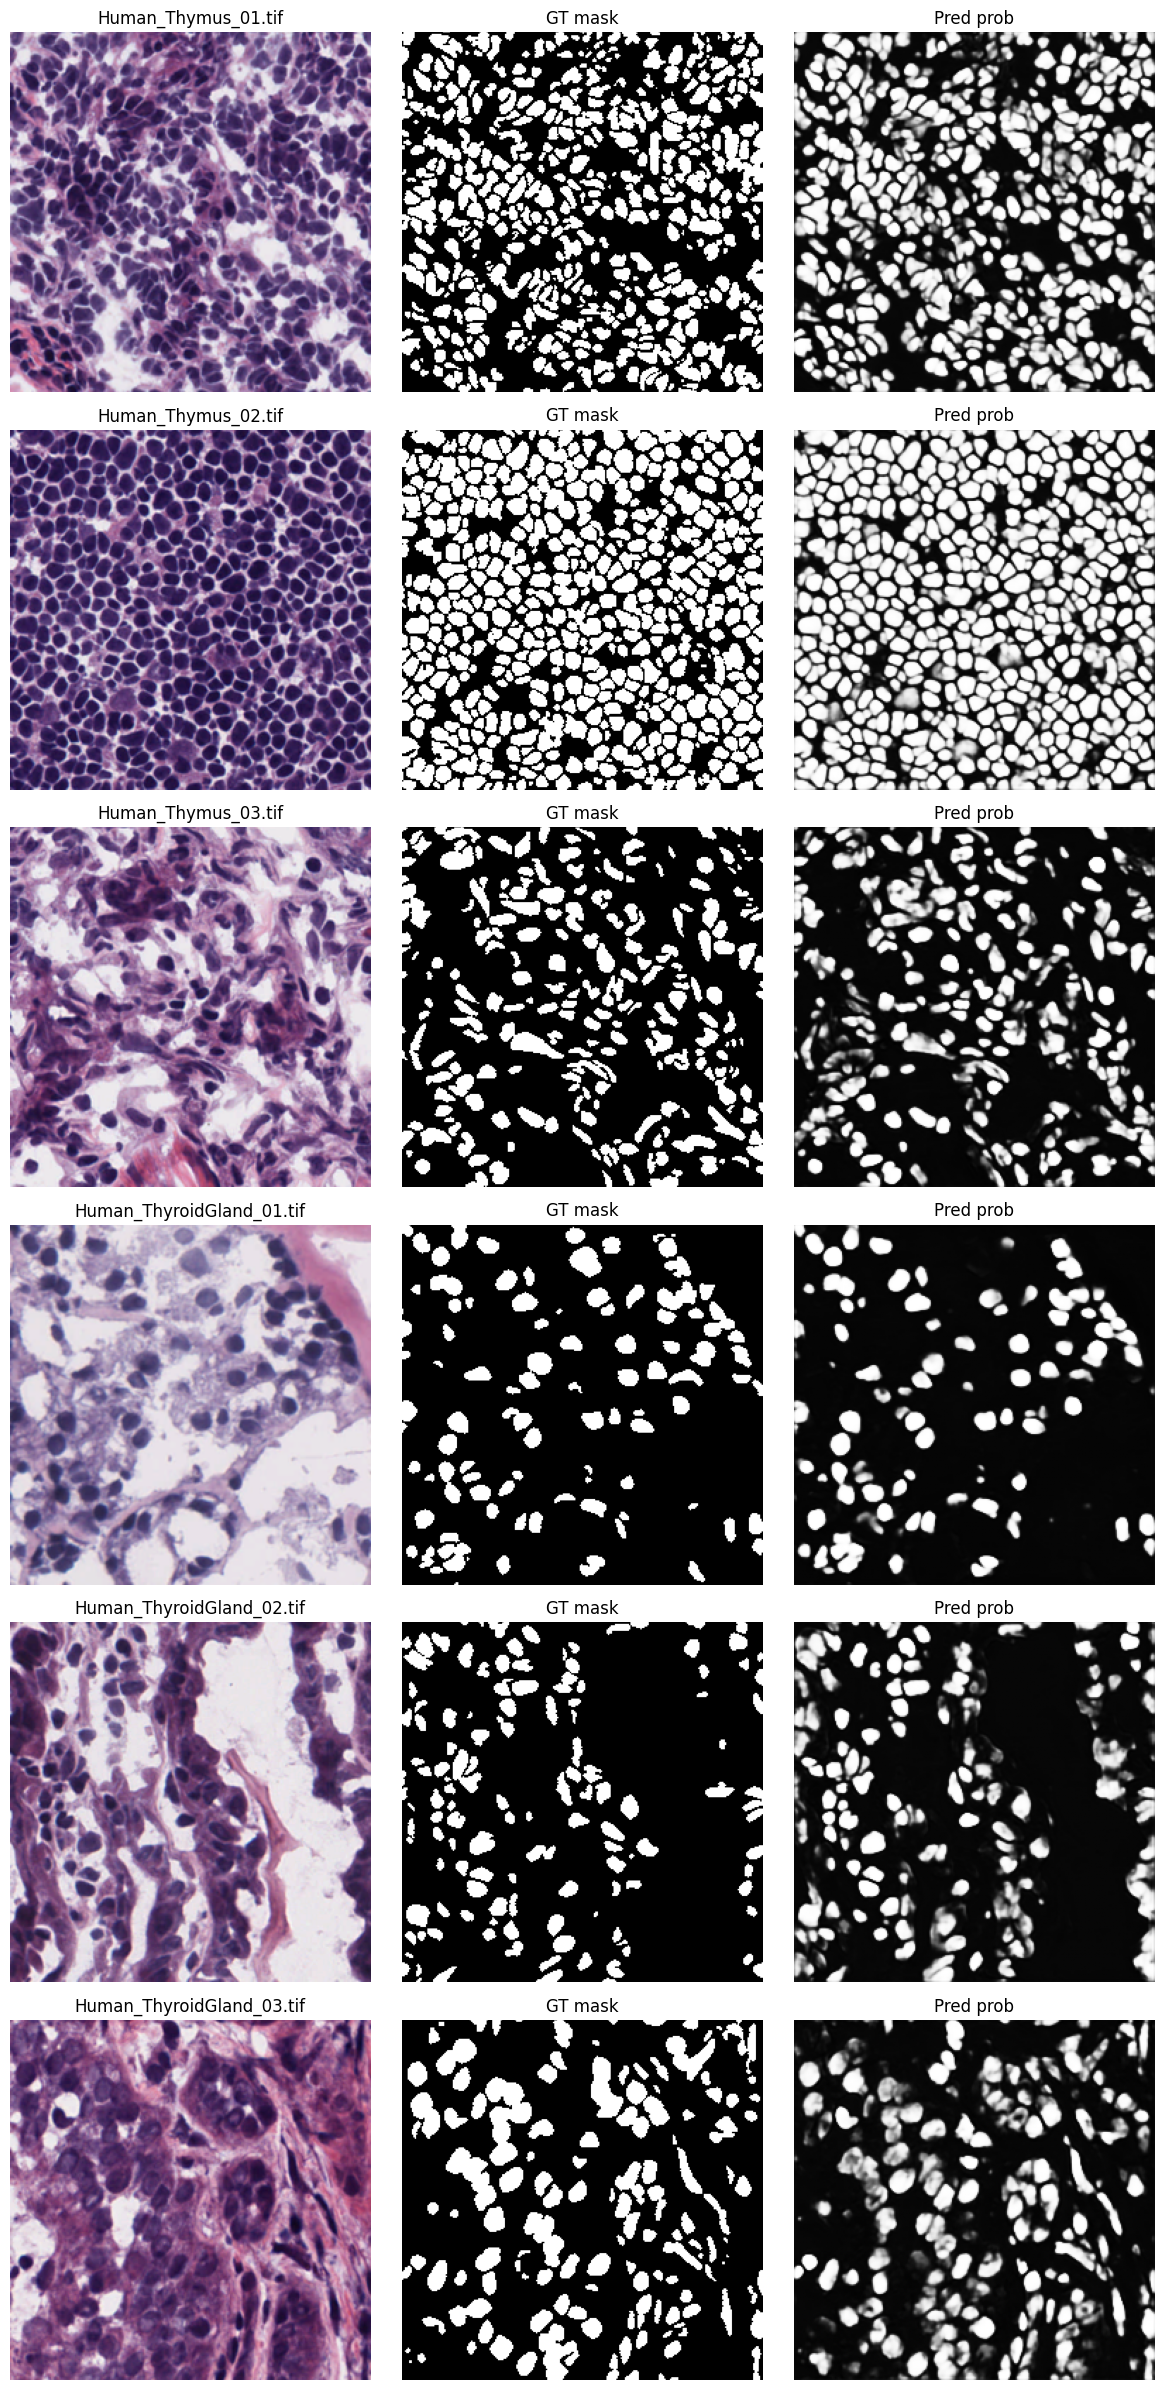

In [ ]:
# JUPYTER/Windows-ready inference + quick viz (paths fixed -> dataset_zip)
import os
import torch
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms

# ---------- PATHS (local, corrected to dataset_zip) ----------
best_model_path = r"C:\Users\User\Desktop\Btech_asmita\unet_project\sam_unet_runs\best_sgx_eunet3plus.pth"
IMG_DIR  = r"C:\Users\User\Desktop\Btech_asmita\unet_project\dataset_zip\images\val"
MASK_DIR = r"C:\Users\User\Desktop\Btech_asmita\unet_project\dataset_zip\masks\val"
SAM_CKPT = r"C:\Users\User\Desktop\Btech_asmita\unet_project\sam_vit_b.pth"

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("⚡ Device:", device)

# ---------- checks ----------
if not os.path.exists(best_model_path):
    raise FileNotFoundError(f"❌ Model file not found: {best_model_path}")
if not os.path.exists(SAM_CKPT):
    raise FileNotFoundError(f"❌ SAM checkpoint not found: {SAM_CKPT}")
if not os.path.isdir(IMG_DIR):
    raise FileNotFoundError(f"❌ IMG_DIR not found: {IMG_DIR}")
if not os.path.isdir(MASK_DIR):
    raise FileNotFoundError(f"❌ MASK_DIR not found: {MASK_DIR}")

# ---------- model architecture (EUNet3PlusSAM must already be defined above) ----------
model = EUNet3PlusSAM(in_ch=3, out_ch=1, base_c=64, sam_c=256).to(device)

# ---------- load SAM and predictor ----------
from segment_anything import sam_model_registry, SamPredictor
from segment_anything.utils.transforms import ResizeLongestSide
import torch.nn.functional as F

sam = sam_model_registry["vit_b"](checkpoint=SAM_CKPT).to(device)
sam.eval()
predictor = SamPredictor(sam)
sam_pre = ResizeLongestSide(sam.image_encoder.img_size)

# ---------- embedding function (same as training cell) ----------
@torch.no_grad()
def sam_embedding_from_rgb(batch_rgb):
    """
    batch_rgb: tensor [B,3,H,W], normalized as in training transforms.
    returns: sam embeddings [B, 256, 32, 32] (float tensor on device)
    """
    import numpy as np
    batch_np = []
    for img in batch_rgb:
        img_np = (img.detach().cpu().moveaxis(0, -1).numpy() * 255).astype(np.uint8)
        batch_np.append(sam_pre.apply_image(img_np))

    batch_np = np.stack(batch_np, axis=0)
    batch_t = torch.as_tensor(batch_np, device=device).permute(0, 3, 1, 2).float()
    embs = predictor.model.image_encoder(batch_t)   # [B,256,H_e,W_e]
    embs = F.interpolate(embs, size=(32, 32), mode="bilinear", align_corners=False)
    return embs

# ---------- load checkpoint weights ----------
checkpoint = torch.load(best_model_path, map_location=device)
model.load_state_dict(checkpoint)
model.eval()
print("🔥 Best EUNet3PlusSAM model loaded successfully on", device)

# ---------- preprocessing (same as dataset) ----------
tf = transforms.Compose([
    transforms.Resize((256,256)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

# ---------- quick inference + visualization on first N val images ----------
val_images = sorted([f for f in os.listdir(IMG_DIR) if f.lower().endswith(('.png','.jpg','.jpeg','.tif'))])
N = min(6, len(val_images))
print(f"Found {len(val_images)} validation images — running inference on {N} samples.")

plt.figure(figsize=(12, 4 * N))
for i, fname in enumerate(val_images[:N]):
    # load image & mask
    img_p = os.path.join(IMG_DIR, fname)
    # mask lookup: try same base names (.png/.tif/(1))
    base = os.path.splitext(fname)[0]
    mask_candidates = [f"{base}.png", f"{base}.tif", f"{base} (1).png", f"{base} (1).tif"]
    mask_path = None
    for c in mask_candidates:
        p = os.path.join(MASK_DIR, c)
        if os.path.exists(p):
            mask_path = p
            break

    img_pil = Image.open(img_p).convert("RGB")
    if mask_path:
        mask_pil = Image.open(mask_path).convert("L").resize((256,256))
    else:
        mask_pil = Image.new("L", (256,256))

    img_t = tf(img_pil).to(device).unsqueeze(0)  # [1,3,256,256]
    with torch.no_grad():
        sam_emb = sam_embedding_from_rgb(img_t)
        logits = model(img_t, sam_emb)        # logits [1,1,256,256]
        probs = torch.sigmoid(logits)[0,0].cpu().numpy()

    # prepare visuals
    img_np = np.array(img_pil.resize((256,256))).astype(np.uint8)
    mask_np = (np.array(mask_pil) > 127).astype(np.uint8)

    # plot: original, true mask, predicted mask
    ax1 = plt.subplot(N, 3, i*3 + 1); ax1.imshow(img_np); ax1.axis('off'); ax1.set_title(fname)
    ax2 = plt.subplot(N, 3, i*3 + 2); ax2.imshow(mask_np, cmap='gray'); ax2.axis('off'); ax2.set_title("GT mask")
    ax3 = plt.subplot(N, 3, i*3 + 3); ax3.imshow(probs, cmap='gray'); ax3.axis('off'); ax3.set_title("Pred prob")

plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
import torch

def iou_dice(pred, gt, eps=1e-6):
    """
    pred : predicted mask  (NumPy array or PyTorch tensor), float in [0,1]
    gt   : ground truth mask (NumPy array or PyTorch tensor), float in [0,1]

    Returns:
        (IoU, Dice) tuple as Python floats
    """

    # convert tensors → numpy
    if isinstance(pred, torch.Tensor):
        pred = pred.detach().cpu().numpy()
    if isinstance(gt, torch.Tensor):
        gt = gt.detach().cpu().numpy()

    # remove extra dims (batch/channel)
    pred = np.squeeze(pred)
    gt   = np.squeeze(gt)

    # binarize at threshold 0.5
    p = pred > 0.5
    g = gt > 0.5

    inter = np.logical_and(p, g).sum()
    union = np.logical_or(p, g).sum()

    # edge case: both masks completely empty
    if union == 0:
        return 1.0, 1.0

    iou  = (inter + eps) / (union + eps)
    dice = (2 * inter + eps) / (p.sum() + g.sum() + eps)

    return float(iou), float(dice)


In [ ]:
import torch
# ensure device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", device)

# instantiate model (make sure the EUNet3PlusSAM class cell was run)
model = EUNet3PlusSAM(in_ch=3, out_ch=1, base_c=64, sam_c=256).to(device)

# params
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable params: {n_params:,}")

# sanity forward pass
with torch.no_grad():
    x = torch.randn(1, 3, 256, 256, device=device)        # dummy image batch
    sam_emb = torch.randn(1, 256, 32, 32, device=device)  # dummy SAM embedding
    logits = model(x, sam_emb)                            # logits [B,1,256,256]
    probs = torch.sigmoid(logits)
print("logits.shape:", logits.shape)
print("probs min/max:", float(probs.min()), float(probs.max()))


Device: cuda
Trainable params: 26,686,065
logits.shape: torch.Size([1, 1, 256, 256])
probs min/max: 0.09623188525438309 0.7789414525032043


In [ ]:
# ================================================================
# 📌 MODEL — EUNet3Plus + Multi-Scale X-Gated SAM Fusion (LOGITS OUTPUT)
# ================================================================
import torch
import torch.nn as nn
import torch.nn.functional as F

# ------------------------------------------------------------
# 🔹 Double Conv Block (Conv → BN → ReLU) × 2
# ------------------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.seq = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.seq(x)


# ------------------------------------------------------------
# 🔹 X-Gated Fusion Block (multi-scale conv + SE + residual)
# ------------------------------------------------------------
class XGatedFusion(nn.Module):
    def __init__(self, c_x, c_s):
        super().__init__()

        # match channels (SAM → UNet)
        self.proj_s = nn.Conv2d(c_s, c_x, 1)
        self.proj_x = nn.Conv2d(c_x, c_x, 1)

        # gating signals
        self.f_gate = nn.Conv2d(c_x, c_x, 1)
        self.s_gate = nn.Conv2d(c_x, c_x, 1)

        # multi-scale conv branch
        self.conv3 = nn.Conv2d(c_x, c_x, 3, padding=1)
        self.conv5 = nn.Conv2d(c_x, c_x, 5, padding=2)

        # channel SE attention
        hidden = max(c_x // 4, 8)
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(c_x, hidden, 1),
            nn.ReLU(),
            nn.Conv2d(hidden, c_x, 1),
            nn.Sigmoid(),
        )

        # output projection + normalization
        self.out = nn.Conv2d(c_x, c_x, 1)
        self.gn = nn.GroupNorm(8 if c_x >= 8 else 1, c_x)

    def forward(self, x_u, x_sam):
        # channel match
        x_u = self.proj_x(x_u)
        x_sam = self.proj_s(x_sam)

        # gating
        g_u = torch.sigmoid(self.f_gate(x_u))
        g_s = torch.sigmoid(self.s_gate(x_sam))

        # gated mixing
        x = x_u * g_s + x_sam * g_u

        # multi-scale conv + SE
        x_ms = self.conv3(x) + self.conv5(x)
        x = x_ms * self.se(x_ms)

        # residual + GN
        x = self.out(x) + x
        return self.gn(x)


# ------------------------------------------------------------
# 🔹 Main EUNet3PlusSAM Model
# ------------------------------------------------------------
class EUNet3PlusSAM(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base_c=64, sam_c=256):
        super().__init__()

        # ---------------- Encoder ----------------
        self.e1 = DoubleConv(in_ch, base_c)          # 256×256
        self.e2 = DoubleConv(base_c, base_c * 2)     # 128×128
        self.e3 = DoubleConv(base_c * 2, base_c * 4) # 64×64
        self.e4 = DoubleConv(base_c * 4, base_c * 8) # 32×32
        self.pool = nn.MaxPool2d(2)

        # ---------------- SAM Fusion ----------------
        self.fuse1 = XGatedFusion(base_c,     sam_c)
        self.fuse2 = XGatedFusion(base_c * 2, sam_c)
        self.fuse3 = XGatedFusion(base_c * 4, sam_c)
        self.fuse4 = XGatedFusion(base_c * 8, sam_c)

        # ---------------- Decoder (EUNet3+) ----------------
        self.dec4 = DoubleConv(base_c * 8, base_c * 8)
        self.dec3 = DoubleConv(base_c + base_c*2 + base_c*4 + base_c*8, base_c * 4)
        self.dec2 = DoubleConv(base_c + base_c*2 + base_c*4, base_c * 2)
        self.dec1 = DoubleConv(base_c + base_c*2, base_c)

        self.outc = nn.Conv2d(base_c, out_ch, 1)

    def forward(self, x, sam_emb):

        # ---------------- Encoder ----------------
        x1 = self.e1(x)
        x2 = self.e2(self.pool(x1))
        x3 = self.e3(self.pool(x2))
        x4 = self.e4(self.pool(x3))

        # ---------------- Resize SAM embeddings ----------------
        sam4 = F.interpolate(sam_emb, size=x4.shape[-2:], mode="bilinear", align_corners=False)
        sam3 = F.interpolate(sam_emb, size=x3.shape[-2:], mode="bilinear", align_corners=False)
        sam2 = F.interpolate(sam_emb, size=x2.shape[-2:], mode="bilinear", align_corners=False)
        sam1 = F.interpolate(sam_emb, size=x1.shape[-2:], mode="bilinear", align_corners=False)

        # ---------------- Fusion ----------------
        x4f = self.fuse4(x4, sam4)
        x3f = self.fuse3(x3, sam3)
        x2f = self.fuse2(x2, sam2)
        x1f = self.fuse1(x1, sam1)

        # ---------------- Decoder ----------------
        d4 = self.dec4(x4f)

        # d3 level (64×64)
        x1_ds4 = F.max_pool2d(x1f, 4)
        x2_ds2 = F.max_pool2d(x2f, 2)
        d3 = self.dec3(torch.cat([
            x1_ds4,
            x2_ds2,
            x3f,
            F.interpolate(d4, scale_factor=2, mode="bilinear", align_corners=False)
        ], dim=1))

        # d2 level (128×128)
        d2 = self.dec2(torch.cat([
            F.max_pool2d(x1f, 2),
            x2f,
            F.interpolate(d3, scale_factor=2, mode="bilinear", align_corners=False)
        ], dim=1))

        # d1 level (256×256)
        d1 = self.dec1(torch.cat([
            x1f,
            F.interpolate(d2, scale_factor=2, mode="bilinear", align_corners=False)
        ], dim=1))

        # LOGITS → sigmoid applied later
        return self.outc(d1)


In [ ]:
# ================================================================
# 📌 Load Trained EUNet3PlusSAM Model (Jupyter / Local GPU Safe)
# ================================================================
import torch
import os

# device
device = "cuda" if torch.cuda.is_available() else "cpu"
print("⚡ Device:", device)

# your saved model path (update only if filename changed)
best_model_path = r"C:\Users\User\Desktop\Btech_asmita\unet_project\sam_unet_runs\best_sgx_eunet3plus.pth"

# verify file exists
if not os.path.exists(best_model_path):
    raise FileNotFoundError(f"❌ Checkpoint not found:\n{best_model_path}")

# instantiate architecture (must match training)
model = EUNet3PlusSAM(in_ch=3, out_ch=1, base_c=64, sam_c=256).to(device)

# load weights
checkpoint = torch.load(best_model_path, map_location=device)

# If model was saved using torch.save(model.state_dict())
model.load_state_dict(checkpoint)

# if saved using torch.save({"model": model.state_dict(), ...})
# use this instead:
# model.load_state_dict(checkpoint["model"])

model.eval()

print("✅ Model loaded successfully from:")
print(best_model_path)


⚡ Device: cuda
✅ Model loaded successfully from:
C:\Users\User\Desktop\Btech_asmita\unet_project\sam_unet_runs\best_sgx_eunet3plus.pth


C:\Users\User\AppData\Local\Temp\ipykernel_18452\3148354192.py:22: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(best_model_path, map_location=device

⚡ Device: cuda
🔍 Total validation images: 6
🟢 Valid with masks: 6


C:\Users\User\AppData\Local\Temp\ipykernel_18452\988444233.py:89: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.no_grad(), torch.cuda.amp.autocast(enabled=(device == "cuda")):


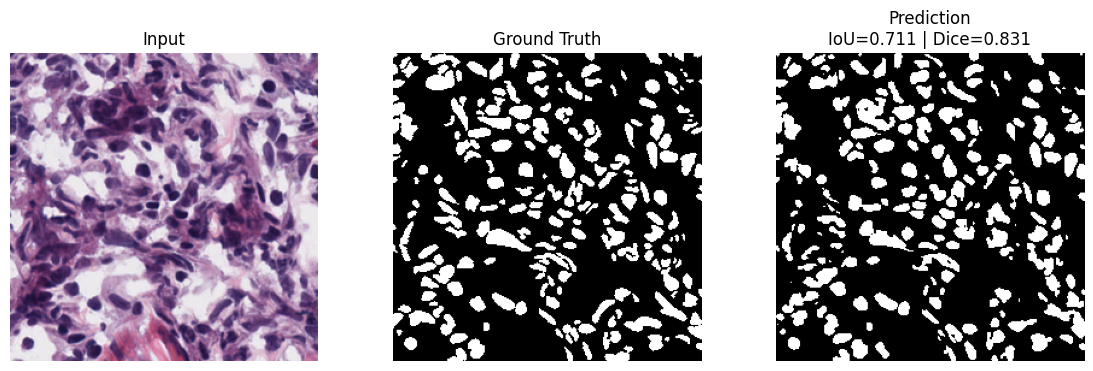

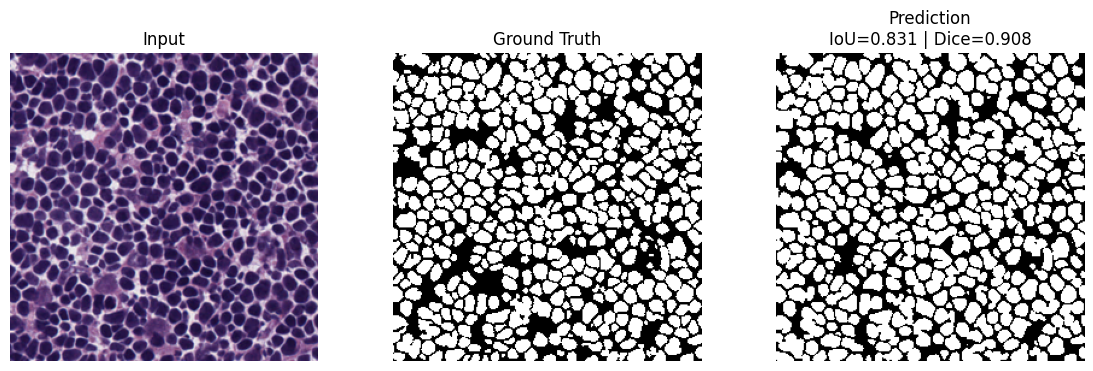

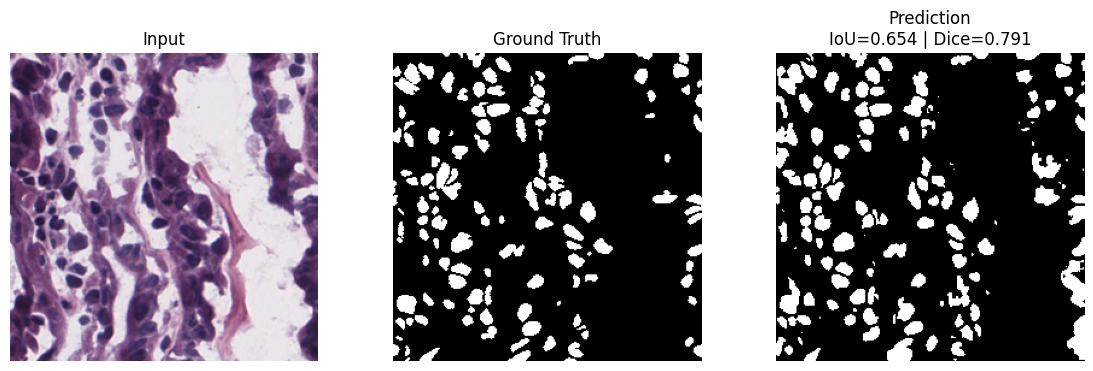

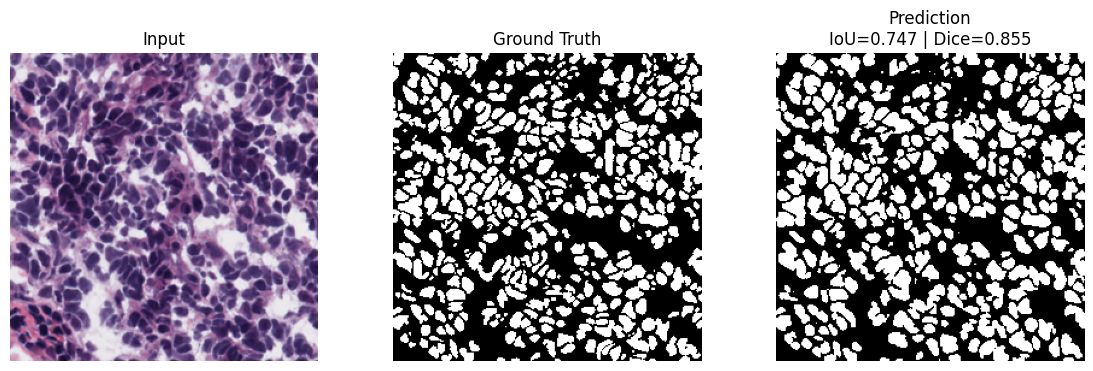

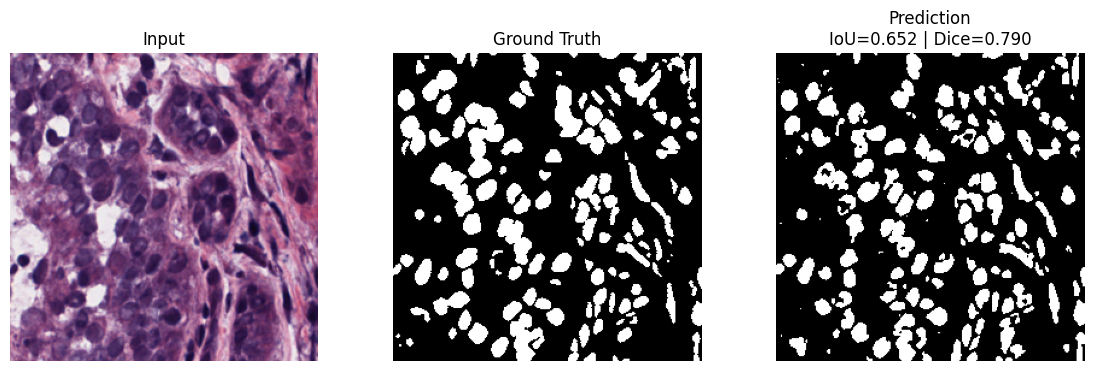


==================== FINAL METRICS ====================
🔥 Average IoU  : 0.7192
🔥 Average Dice: 0.8349


In [ ]:
import os, random
import torch
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms

# ---------------- PATHS (LOCAL WINDOWS) ----------------
IMG_DIR  = r"C:\Users\User\Desktop\Btech_asmita\unet_project\dataset_zip\images\val"
MASK_DIR = r"C:\Users\User\Desktop\Btech_asmita\unet_project\dataset_zip\masks\val"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("⚡ Device:", device)

# ---------------- TRANSFORM (same as training) ----------------
tf_vis = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# ---------------- Metrics ----------------
def iou_dice(pred, gt, eps=1e-6):
    pred = (pred > 0.5).astype(np.float32)
    gt   = (gt > 0.5).astype(np.float32)

    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum() - inter
    iou  = (inter + eps) / (union + eps)
    dice = (2 * inter + eps) / (pred.sum() + gt.sum() + eps)
    return iou, dice


# ---------------- Collect valid samples ----------------
val_imgs = sorted([f for f in os.listdir(IMG_DIR)
                   if f.lower().endswith(('.png','.jpg','.jpeg','.tif'))])

valid = []
for name in val_imgs:
    base = os.path.splitext(name)[0]
    for cand in [
        f"{base}.png", f"{base}.jpg", f"{base}.jpeg", f"{base}.tif",
        f"{base} (1).png", f"{base} (1).jpg", f"{base} (1).tif"
    ]:
        if os.path.exists(os.path.join(MASK_DIR, cand)):
            valid.append(name)
            break

print(f"🔍 Total validation images: {len(val_imgs)}")
print(f"🟢 Valid with masks: {len(valid)}")

if len(valid) == 0:
    raise RuntimeError("❌ No valid samples found.")


# ---------------- Pick 5 random samples ----------------
samples = random.sample(valid, min(5, len(valid)))
ious, dices = [], []

model.eval()

for name in samples:
    # load image
    img_path = os.path.join(IMG_DIR, name)
    img = Image.open(img_path).convert("RGB")
    img_disp = img.resize((256, 256))
    img_t = tf_vis(img).unsqueeze(0).to(device)

    # load mask
    base = os.path.splitext(name)[0]
    mask = None
    for suffix in ["", " (1)"]:
        for ext in ["png", "jpg", "jpeg", "tif"]:
            p = os.path.join(MASK_DIR, f"{base}{suffix}.{ext}")
            if os.path.exists(p):
                mask = Image.open(p).convert("L")
                break
        if mask is not None:
            break

    if mask is None:
        print(f"⚠️ Mask missing for {name}, skipping.")
        continue

    gt = (np.array(mask.resize((256, 256))) > 127).astype(np.float32)

    # ------- Prediction -------
    with torch.no_grad(), torch.cuda.amp.autocast(enabled=(device == "cuda")):
        sam_emb = sam_embedding_from_rgb(img_t)
        logits = model(img_t, sam_emb)
        prob_map = torch.sigmoid(logits).squeeze().cpu().numpy()

    pred_bin = prob_map > 0.5
    i, d = iou_dice(prob_map, gt)
    ious.append(i)
    dices.append(d)

    # ------- Visualization -------
    plt.figure(figsize=(14, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(img_disp)
    plt.title("Input")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(gt, cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(pred_bin, cmap="gray")
    plt.title(f"Prediction\nIoU={i:.3f} | Dice={d:.3f}")
    plt.axis("off")

    plt.show()


# ---------------- Final average metrics ----------------
print("\n==================== FINAL METRICS ====================")
print(f"🔥 Average IoU  : {np.mean(ious):.4f}")
print(f"🔥 Average Dice: {np.mean(dices):.4f}")
print("========================================================")


🔍 Running phenotypic clustering on 4 random validation samples...

🖼 Image: Human_ThyroidGland_03.tif
🔬 Performing phenotypic clustering of nuclei...
🧬 Nuclei detected: 157


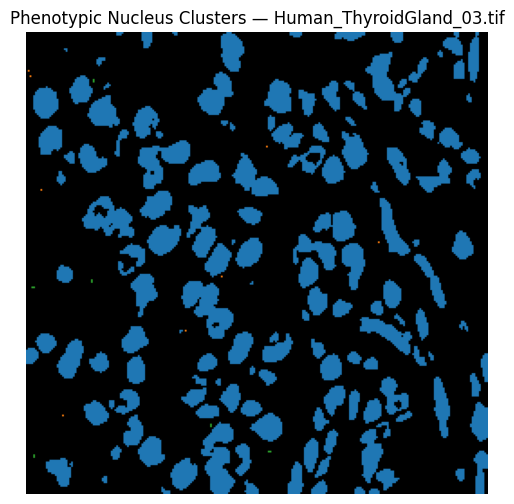

📌 PHENOTYPE GROUP COUNTS
  Cluster 0: 143 nuclei
  Cluster 1: 8 nuclei
  Cluster 2: 6 nuclei

🖼 Image: Human_ThyroidGland_02.tif
🔬 Performing phenotypic clustering of nuclei...
🧬 Nuclei detected: 141


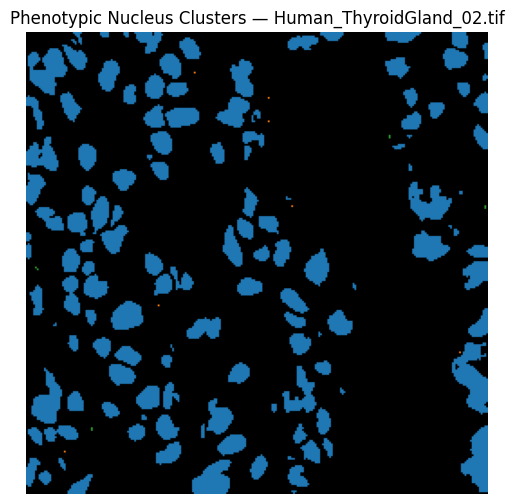

📌 PHENOTYPE GROUP COUNTS
  Cluster 0: 130 nuclei
  Cluster 1: 7 nuclei
  Cluster 2: 4 nuclei

🖼 Image: Human_Thymus_01.tif
🔬 Performing phenotypic clustering of nuclei...
🧬 Nuclei detected: 262


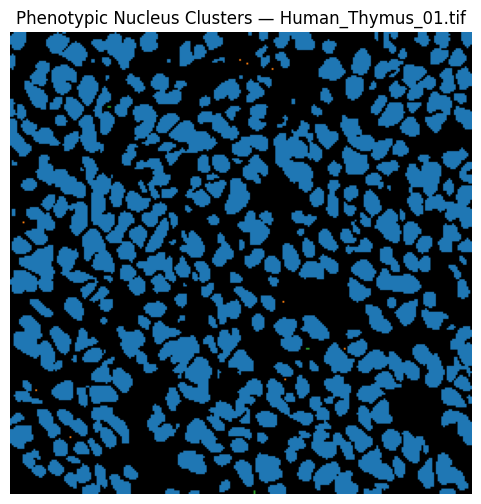

📌 PHENOTYPE GROUP COUNTS
  Cluster 0: 250 nuclei
  Cluster 1: 9 nuclei
  Cluster 2: 3 nuclei

🖼 Image: Human_Thymus_03.tif
🔬 Performing phenotypic clustering of nuclei...
🧬 Nuclei detected: 195


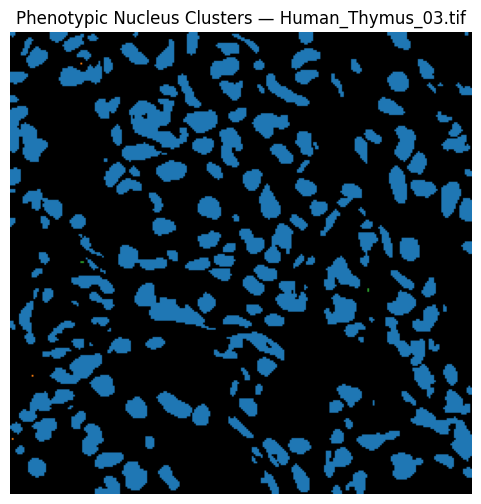

📌 PHENOTYPE GROUP COUNTS
  Cluster 0: 190 nuclei
  Cluster 1: 3 nuclei
  Cluster 2: 2 nuclei


In [ ]:
# ================================================================
# 🔥 Phenotypic clustering for 4 random validation images (Jupyter-ready)
# ================================================================
import random
import os
import numpy as np
import cv2
import skimage.measure as measure
from skimage.color import rgb2lab
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from PIL import Image
import torch

print("🔍 Running phenotypic clustering on 4 random validation samples...")

# pick 4 random validation images
sample_imgs = random.sample(valid, min(4, len(valid)))

for name in sample_imgs:
    print("\n==============================================")
    print("🖼 Image:", name)

    # ---------------- Load image and GT (same as your inference loop) ----------------
    img = Image.open(os.path.join(IMG_DIR, name)).convert("RGB")
    img_disp = img.resize((256, 256))
    img_t = tf_vis(img).unsqueeze(0).to(device)

    # ---------------- Model prediction ----------------
    with torch.no_grad():
        sam_emb = sam_embedding_from_rgb(img_t)
        prob_map = torch.sigmoid(model(img_t, sam_emb)).cpu().numpy()[0, 0]

    # ================================================================
    # 📌 PHENOTYPIC CLUSTERING (Original Code)
    # ================================================================
    print("🔬 Performing phenotypic clustering of nuclei...")

    pred_mask = (prob_map > 0.5).astype(np.uint8)
    num_labels, labels = cv2.connectedComponents(pred_mask)

    if num_labels <= 1:
        print("⚠ No nuclei detected for clustering.")
        continue

    print("🧬 Nuclei detected:", num_labels - 1)

    img_np = np.array(img_disp)
    lab = rgb2lab(img_np)
    features = []

    for k in range(1, num_labels):
        # create single-object mask for this label
        mask_k = (labels == k).astype(np.uint8)

        # regionprops expects a 2D array where foreground==1
        props = measure.regionprops(mask_k)
        if len(props) == 0:
            # skip tiny/invalid components
            continue
        region = props[0]
        area = region.area
        perim = region.perimeter + 1e-6
        roundness = 4 * np.pi * area / (perim * perim)

        # get LAB color values under the mask
        color_vals = lab[mask_k == 1]
        if color_vals.size == 0:
            # fallback if no pixels (very unlikely)
            mean_color = np.array([0.0, 0.0, 0.0])
        else:
            mean_color = color_vals.mean(axis=0)

        features.append([area, roundness, mean_color[0], mean_color[1], mean_color[2]])

    features = np.array(features)
    if features.shape[0] == 0:
        print("⚠ No valid nucleus features extracted, skipping clustering.")
        continue

    k = 3  # number of phenotype groups
    kmeans = KMeans(n_clusters=k, random_state=42)
    cluster_labels = kmeans.fit_predict(features)

    # ---------------- Visualization ----------------
    colors = plt.cm.tab10(np.linspace(0, 1, 10))
    cluster_vis = np.zeros((256, 256, 3), dtype=np.uint8)

    for idx, k_idx in enumerate(range(1, num_labels)):
        if idx >= len(cluster_labels):
            break
        c = cluster_labels[idx]
        color = (colors[c][:3] * 255).astype(np.uint8)
        cluster_vis[labels == k_idx] = color

    plt.figure(figsize=(6, 6))
    plt.imshow(cluster_vis)
    plt.title(f"Phenotypic Nucleus Clusters — {name}")
    plt.axis("off")
    plt.show()

    # ---------------- Statistics ----------------
    print("📌 PHENOTYPE GROUP COUNTS")
    unique, counts = np.unique(cluster_labels, return_counts=True)
    for u, cnt in zip(unique, counts):
        print(f"  Cluster {u}: {cnt} nuclei")


🔬 Performing advanced phenotypic clustering of nuclei...
🧬 Nuclei detected: 195
✅ Extracted features for 182 nuclei.
✅ Extracted deep features shape: (182, 512)
Combined feature shape: (182, 518)
PCA output shape: (182, 40)
Clustering done (method=HDBSCAN). Unique clusters (including -1): [-1]


c:\Users\User\Desktop\Btech_asmita\.venv\lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\User\Desktop\Btech_asmita\.venv\lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


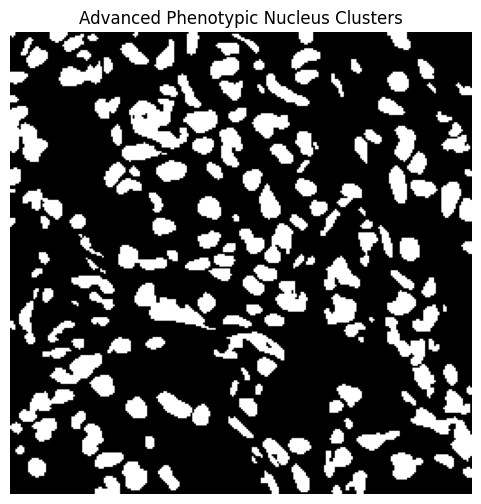

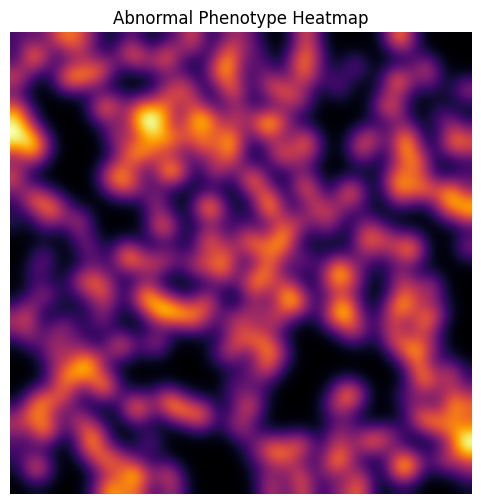


📌 ADVANCED PHENOTYPE STATISTICS
⚠ Abnormal phenotype (-1): 182 nuclei


In [ ]:
# ================================================================
# 🔥 ADVANCED PHENOTYPIC CLUSTERING OF NUCLEI (Robust Jupyter Version)
# ================================================================
print("🔬 Performing advanced phenotypic clustering of nuclei...")

import numpy as np
import cv2
import matplotlib.pyplot as plt
import skimage.measure as measure
from skimage.color import rgb2lab
from skimage.feature import graycomatrix, graycoprops
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import hdbscan
import torchvision.models as models
import torchvision.transforms as T
import torch
from PIL import Image

# ---------------- 0) Basic checks ----------------
if 'prob_map' not in globals():
    raise RuntimeError("prob_map not found in namespace — run prediction first.")
if 'img_disp' not in globals():
    raise RuntimeError("img_disp (resized PIL image) not found — run prediction first.")

# convert prob_map to binary mask
pred_mask = (prob_map > 0.5).astype(np.uint8)
num_labels, labels = cv2.connectedComponents(pred_mask)

if num_labels <= 1:
    print("⚠ No nuclei detected for clustering.")
    raise SystemExit

print("🧬 Nuclei detected:", num_labels - 1)

# image / lab conversion
img_np = np.array(img_disp)  # expected 256x256x3
lab = rgb2lab(img_np)
features = []
patches = []

# ---------------- 1) Extract morphology + color + texture ----------------
for k in range(1, num_labels):
    mask_k = (labels == k).astype(np.uint8)
    # skip tiny components
    if mask_k.sum() < 5:
        continue

    props = measure.regionprops(mask_k.astype(np.uint8))
    if len(props) == 0:
        continue
    region = props[0]

    area = float(region.area)
    perim = float(region.perimeter) + 1e-6
    roundness = float(4 * np.pi * area / (perim * perim))

    # LAB color mean under mask
    color_vals = lab[mask_k == 1]
    mean_color = color_vals.mean(axis=0) if color_vals.size else np.array([0.0, 0.0, 0.0])

    # GLCM texture: compute within ROI bounding box to avoid huge zero padding
    y0, x0, y1, x1 = region.bbox
    roi_rgb = img_np[y0:y1, x0:x1]
    roi_mask = mask_k[y0:y1, x0:x1]
    if roi_rgb.size == 0 or roi_mask.sum() < 5:
        texture = 0.0
    else:
        roi_gray = cv2.cvtColor(roi_rgb, cv2.COLOR_RGB2GRAY)
        # quantize to 64 levels to speed up GLCM
        levels = 64
        roi_q = np.floor((roi_gray.astype(np.float32) / 256.0) * levels).astype(np.uint8)
        # apply mask: set background to 0 (still included in matrix; acceptable)
        try:
            glcm = graycomatrix(roi_q, distances=[1], angles=[0], levels=levels, symmetric=True, normed=True)
            texture = float(graycoprops(glcm, 'contrast')[0, 0])
        except Exception:
            texture = 0.0

    features.append([area, roundness, float(mean_color[0]), float(mean_color[1]), float(mean_color[2]), texture])
    patches.append(roi_rgb if roi_rgb.size else np.zeros((8,8,3), dtype=np.uint8))

features = np.array(features)
if features.shape[0] == 0:
    raise RuntimeError("No valid nucleus features extracted — aborting clustering.")

print(f"✅ Extracted features for {features.shape[0]} nuclei.")

# ---------------- 2) Deep feature embedding (ResNet18) ----------------
# load ResNet backbone and strip classifier; handle torchvision API differences
try:
    # torchvision >= 0.13
    try:
        weights = models.ResNet18_Weights.DEFAULT
        backbone = models.resnet18(weights=weights)
    except Exception:
        backbone = models.resnet18(pretrained=True)
except Exception:
    # final fallback — uninitialized model
    print("⚠ Could not load pretrained ResNet18 weights. Using random init.")
    backbone = models.resnet18(pretrained=False)

extractor = torch.nn.Sequential(*list(backbone.children())[:-1]).to(device).eval()

trf = T.Compose([
    T.Resize((64, 64)),
    T.ToTensor(),
    T.Normalize([0.5, 0.5, 0.5],[0.5, 0.5, 0.5])
])

deep_feats = []
with torch.no_grad():
    for p in patches:
        if p.size == 0:
            deep_feats.append(np.zeros(512, dtype=np.float32))
            continue
        t = trf(Image.fromarray(p)).unsqueeze(0).to(device)
        emb = extractor(t).cpu().numpy().reshape(-1)
        deep_feats.append(emb)

deep_feats = np.array(deep_feats)
print(f"✅ Extracted deep features shape: {deep_feats.shape}")

# ---------------- 3) Combine features ----------------
full_feat = np.hstack([features, deep_feats])  # shape: (n_instances, feat_dim)
print("Combined feature shape:", full_feat.shape)

# ---------------- 4) Dimensionality reduction (PCA) — guard n_components ----------------
n_samples, n_dim = full_feat.shape
n_components = min(40, n_samples, n_dim)
if n_components < 2:
    X = full_feat  # nothing to reduce
else:
    pca = PCA(n_components=n_components)
    X = pca.fit_transform(full_feat)

print("PCA output shape:", X.shape)

# ---------------- 5) Clustering — use HDBSCAN if enough samples else KMeans ----------------
if X.shape[0] >= 10:
    try:
        clusterer = hdbscan.HDBSCAN(min_cluster_size=max(5, X.shape[0]//10), min_samples=5)
        cluster_labels = clusterer.fit_predict(X)   # -1 are outliers
        method = "HDBSCAN"
    except Exception as e:
        print("⚠ HDBSCAN failed:", e, "— falling back to KMeans")
        k = min(3, max(2, X.shape[0]//5))
        cluster_labels = KMeans(n_clusters=k, random_state=42).fit_predict(X)
        method = "KMeans"
else:
    k = min(3, max(2, X.shape[0]//2))
    cluster_labels = KMeans(n_clusters=k, random_state=42).fit_predict(X)
    method = "KMeans"

print(f"Clustering done (method={method}). Unique clusters (including -1):", np.unique(cluster_labels))

# ---------------- 6) Visualization ----------------
colors = plt.cm.tab20(np.linspace(0, 1, 20))
cluster_vis = np.zeros((labels.shape[0], labels.shape[1], 3), dtype=np.uint8)

# Map instance index -> cluster label. Note: some small components were skipped; ensure mapping length matches
inst_idx = 0
for k in range(1, num_labels):
    mask_k = (labels == k)
    if mask_k.sum() < 5:
        continue
    lab_id = cluster_labels[inst_idx] if inst_idx < len(cluster_labels) else -1
    if lab_id == -1:
        color = np.array([255,255,255], dtype=np.uint8)
    else:
        color = (colors[int(lab_id) % 20][:3] * 255).astype(np.uint8)
    cluster_vis[mask_k] = color
    inst_idx += 1

plt.figure(figsize=(6,6))
plt.imshow(cluster_vis)
plt.title("Advanced Phenotypic Nucleus Clusters")
plt.axis("off")
plt.show()

# ---------------- 7) Spatial heatmap of abnormal nuclei ----------------
abn = np.zeros_like(pred_mask, dtype=float)
inst_idx = 0
for k in range(1, num_labels):
    mask_k = (labels == k)
    if mask_k.sum() < 5:
        continue
    if inst_idx < len(cluster_labels) and cluster_labels[inst_idx] == -1:
        abn[mask_k] = 1.0
    inst_idx += 1

abn = cv2.GaussianBlur(abn.astype(float), (0,0), sigmaX=6)
plt.figure(figsize=(6,6))
plt.imshow(abn, cmap="inferno")
plt.title("Abnormal Phenotype Heatmap")
plt.axis("off")
plt.show()

# ---------------- 8) Statistics ----------------
print("\n📌 ADVANCED PHENOTYPE STATISTICS")
unique, counts = np.unique(cluster_labels, return_counts=True)
for u, c in zip(unique, counts):
    if u == -1:
        print(f"⚠ Abnormal phenotype (-1): {c} nuclei")
    else:
        print(f"  Cluster {u}: {c} nuclei")


🔬 Extracting nucleus features + PCA (on this image only)...
🧬 Nuclei detected in this image: 195


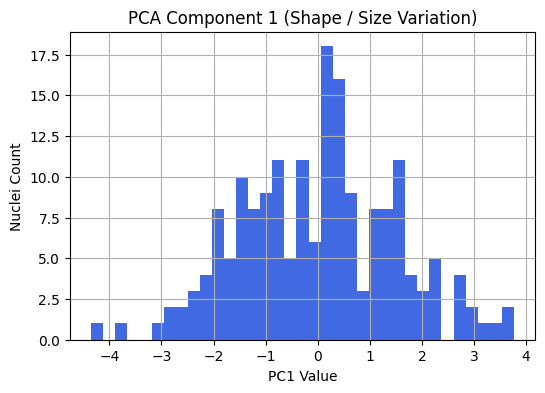

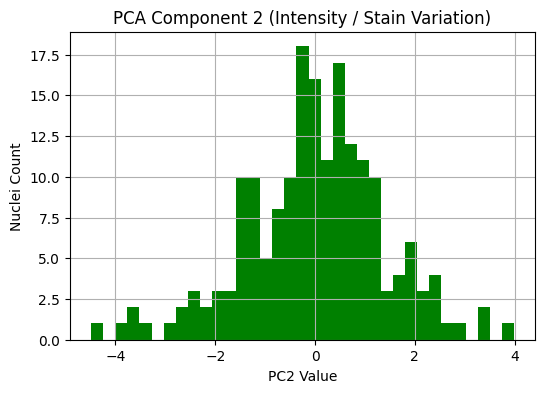

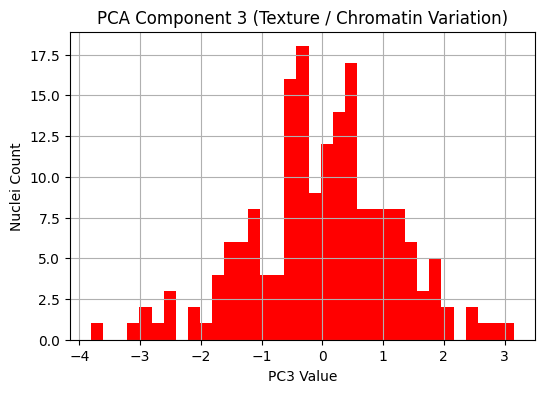


📌 PCA Explained Variance Ratio
 PC1 = 0.320
 PC2 = 0.283
 PC3 = 0.203
💾 Saved table: C:\Users\User\Desktop\Btech_asmita\unet_project\sam_unet_runs\PCA_features_single_image.csv


In [ ]:
# ================================================================
# 🔬 Extracting nucleus features + PCA (on this image only) — Jupyter-ready
# ================================================================
print("🔬 Extracting nucleus features + PCA (on this image only)...")

import numpy as np, cv2
import matplotlib.pyplot as plt
from skimage.measure import regionprops
from skimage.color import rgb2lab
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd
import os

# ---------- checks ----------
if 'prob_map' not in globals():
    raise RuntimeError("prob_map not found — run the prediction step first.")
if 'img_disp' not in globals():
    raise RuntimeError("img_disp (PIL image 256×256) not found — run the prediction step first.")

# ---- Step 1: convert prediction mask to components ----
bin_mask = (prob_map > 0.5).astype(np.uint8)
num_labels, labels = cv2.connectedComponents(bin_mask)

if num_labels <= 1:
    print("⚠ No nuclei detected — PCA skipped.")
else:
    print(f"🧬 Nuclei detected in this image: {num_labels - 1}")

    img_np = np.array(img_disp)
    lab = rgb2lab(img_np)
    features = []

    # ---- Step 2: extract features nucleus-wise ----
    for k in range(1, num_labels):
        mask = (labels == k).astype(np.uint8)
        if mask.sum() < 5:
            # skip very small components
            continue

        props = regionprops(mask.astype(np.uint8))
        if len(props) == 0:
            continue
        region = props[0]

        area = float(region.area)
        perim = float(region.perimeter) + 1e-6
        roundness = float(4 * np.pi * area / (perim * perim))

        # intensity & texture on red channel (approx.)
        red_vals = img_np[:, :, 0][mask == 1].astype(np.float32)
        mean_intensity = float(red_vals.mean()) if red_vals.size else 0.0
        texture = float(red_vals.var()) if red_vals.size else 0.0

        # LAB color mean
        color_vals = lab[mask == 1]
        if color_vals.size:
            mean_l, mean_a, mean_b = [float(v) for v in color_vals.mean(axis=0)]
        else:
            mean_l = mean_a = mean_b = 0.0

        features.append([area, roundness, mean_intensity, texture, mean_l, mean_a, mean_b])

    features = np.array(features)
    if features.shape[0] == 0:
        print("⚠ No valid nucleus features extracted — PCA skipped.")
    else:
        # ---- Step 3: Z-score normalization ----
        scaler = StandardScaler()
        features_norm = scaler.fit_transform(features)

        # ---- Step 4: PCA (3 components) ----
        n_comp = min(3, features_norm.shape[0], features_norm.shape[1])
        pca = PCA(n_components=n_comp)
        feats_pca = pca.fit_transform(features_norm)
        # ensure 3 columns for plotting even if n_comp < 3
        if feats_pca.shape[1] < 3:
            # pad with zeros
            pad = np.zeros((feats_pca.shape[0], 3 - feats_pca.shape[1]), dtype=feats_pca.dtype)
            feats_pca = np.hstack([feats_pca, pad])

        PC1, PC2, PC3 = feats_pca[:,0], feats_pca[:,1], feats_pca[:,2]

        # ---- Step 5: Visualize each PCA separately ----
        plt.figure(figsize=(6,4))
        plt.hist(PC1, bins=35, color='royalblue')
        plt.title("PCA Component 1 (Shape / Size Variation)")
        plt.xlabel("PC1 Value"); plt.ylabel("Nuclei Count"); plt.grid(True)
        plt.show()

        plt.figure(figsize=(6,4))
        plt.hist(PC2, bins=35, color='green')
        plt.title("PCA Component 2 (Intensity / Stain Variation)")
        plt.xlabel("PC2 Value"); plt.ylabel("Nuclei Count"); plt.grid(True)
        plt.show()

        plt.figure(figsize=(6,4))
        plt.hist(PC3, bins=35, color='red')
        plt.title("PCA Component 3 (Texture / Chromatin Variation)")
        plt.xlabel("PC3 Value"); plt.ylabel("Nuclei Count"); plt.grid(True)
        plt.show()

        print("\n📌 PCA Explained Variance Ratio")
        for i in range(n_comp):
            print(f" PC{i+1} = {pca.explained_variance_ratio_[i]:.3f}")

        # ---- Save table with features + PCA ----
        columns = ["Area","Roundness","Intensity","Texture","L","A","B","PC1","PC2","PC3"]
        df = pd.DataFrame(np.hstack([features, feats_pca]), columns=columns)
        save_dir = r"C:\Users\User\Desktop\Btech_asmita\unet_project\sam_unet_runs"
        os.makedirs(save_dir, exist_ok=True)
        save_path = os.path.join(save_dir, "PCA_features_single_image.csv")
        df.to_csv(save_path, index=False)
        print("💾 Saved table:", save_path)


🔬 Extracting nucleus features + PCA + Visual PCA maps...
🧬 Nuclei detected in this image: 195

📌 PCA Explained Variance Ratio:
 PC1 = 0.320
 PC2 = 0.283
 PC3 = 0.203
🎨 Generating PCA-colored phenotype images...


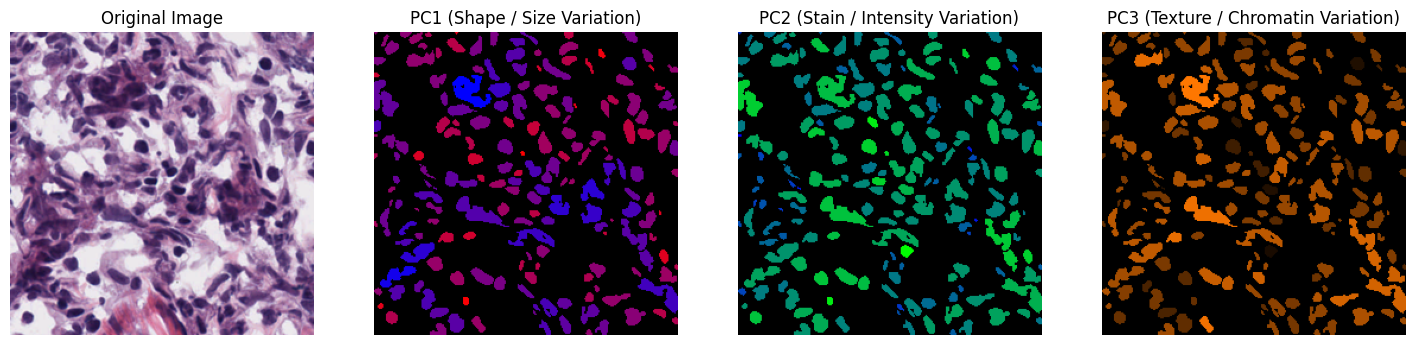

💾 Saved table: C:\Users\User\Desktop\Btech_asmita\unet_project\sam_unet_runs\PCA_features_single_image.csv


In [ ]:
# ================================================================
# 🔬 Extracting nucleus features + PCA + Visual PCA maps (Jupyter-ready)
# ================================================================
print("🔬 Extracting nucleus features + PCA + Visual PCA maps...")

import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.measure import regionprops
from skimage.color import rgb2lab
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd

# ---------- Basic checks ----------
if 'prob_map' not in globals():
    raise RuntimeError("prob_map not found — run the prediction step first.")
if 'img_disp' not in globals():
    raise RuntimeError("img_disp (PIL image 256×256) not found — run the prediction step first.")

# ---- Step 1: convert prediction mask to connected components ----
bin_mask = (prob_map > 0.5).astype(np.uint8)
num_labels, labels = cv2.connectedComponents(bin_mask)

if num_labels <= 1:
    print("⚠ No nuclei detected — PCA skipped.")
else:
    print(f"🧬 Nuclei detected in this image: {num_labels - 1}")

    img_np = np.array(img_disp)
    lab = rgb2lab(img_np)
    features = []
    valid_indices = []  # track mapping from label -> feature row

    # ---- Step 2: extract features nucleus-wise ----
    for k in range(1, num_labels):
        mask = (labels == k).astype(np.uint8)
        if mask.sum() < 5:  # skip tiny components
            continue

        props = regionprops(mask.astype(np.uint8))
        if len(props) == 0:
            continue
        region = props[0]

        area = float(region.area)
        perim = float(region.perimeter) + 1e-6
        roundness = float(4 * np.pi * area / (perim * perim))

        # intensity & texture on red channel (approx.)
        red_vals = img_np[:, :, 0][mask == 1].astype(np.float32)
        mean_intensity = float(red_vals.mean()) if red_vals.size else 0.0
        texture = float(red_vals.var()) if red_vals.size else 0.0

        # LAB color mean
        color_vals = lab[mask == 1]
        if color_vals.size:
            mean_l, mean_a, mean_b = [float(v) for v in color_vals.mean(axis=0)]
        else:
            mean_l = mean_a = mean_b = 0.0

        features.append([area, roundness, mean_intensity, texture, mean_l, mean_a, mean_b])
        valid_indices.append(k)

    features = np.array(features)
    if features.shape[0] == 0:
        print("⚠ No valid nucleus features extracted — PCA skipped.")
    else:
        # ---- Step 3: Normalize features ----
        scaler = StandardScaler()
        features_norm = scaler.fit_transform(features)

        # ---- Step 4: PCA (3 components; guard small n) ----
        n_comp = min(3, features_norm.shape[0], features_norm.shape[1])
        pca = PCA(n_components=n_comp)
        feats_pca = pca.fit_transform(features_norm)

        # pad to 3 components if needed for consistent plotting
        if feats_pca.shape[1] < 3:
            pad = np.zeros((feats_pca.shape[0], 3 - feats_pca.shape[1]), dtype=feats_pca.dtype)
            feats_pca = np.hstack([feats_pca, pad])

        PC1, PC2, PC3 = feats_pca[:, 0], feats_pca[:, 1], feats_pca[:, 2]

        print("\n📌 PCA Explained Variance Ratio:")
        for i in range(min(n_comp, 3)):
            print(f" PC{i+1} = {pca.explained_variance_ratio_[i]:.3f}")

        # ---- Step 5: PCA-based COLOR MAPS ----
        print("🎨 Generating PCA-colored phenotype images...")

        PC1_norm = (PC1 - PC1.min()) / (PC1.max() - PC1.min() + 1e-6)
        PC2_norm = (PC2 - PC2.min()) / (PC2.max() - PC2.min() + 1e-6)
        PC3_norm = (PC3 - PC3.min()) / (PC3.max() - PC3.min() + 1e-6)

        pc1_img = np.zeros((labels.shape[0], labels.shape[1], 3), dtype=np.uint8)
        pc2_img = np.zeros((labels.shape[0], labels.shape[1], 3), dtype=np.uint8)
        pc3_img = np.zeros((labels.shape[0], labels.shape[1], 3), dtype=np.uint8)

        # map valid_indices -> rows in feats_pca
        for idx, k in enumerate(valid_indices):
            mask_k = (labels == k)
            v1, v2, v3 = PC1_norm[idx], PC2_norm[idx], PC3_norm[idx]

            pc1_img[mask_k] = (int(v1 * 255), 0, 255 - int(v1 * 255))      # Blue ↔ Magenta scale
            pc2_img[mask_k] = (0, int(v2 * 255), 255 - int(v2 * 255))      # Green ↔ Cyan scale
            pc3_img[mask_k] = (int(v3 * 255), int(min(v3 * 120, 255)), 0)  # Yellow ↔ Red scale

        # ---- Step 6: Show results ----
        plt.figure(figsize=(18, 5))
        plt.subplot(1, 4, 1); plt.imshow(img_disp); plt.title("Original Image"); plt.axis("off")
        plt.subplot(1, 4, 2); plt.imshow(pc1_img); plt.title("PC1 (Shape / Size Variation)"); plt.axis("off")
        plt.subplot(1, 4, 3); plt.imshow(pc2_img); plt.title("PC2 (Stain / Intensity Variation)"); plt.axis("off")
        plt.subplot(1, 4, 4); plt.imshow(pc3_img); plt.title("PC3 (Texture / Chromatin Variation)"); plt.axis("off")
        plt.show()

        # ---- Step 7: Export CSV with features + PCA ----
        df = pd.DataFrame(
            np.hstack([features, feats_pca]),
            columns=["Area", "Roundness", "Intensity", "Texture", "L", "A", "B", "PC1", "PC2", "PC3"]
        )

        save_dir = r"C:\Users\User\Desktop\Btech_asmita\unet_project\sam_unet_runs"
        os.makedirs(save_dir, exist_ok=True)
        save_path = os.path.join(save_dir, "PCA_features_single_image.csv")
        df.to_csv(save_path, index=False)
        print("💾 Saved table:", save_path)02.



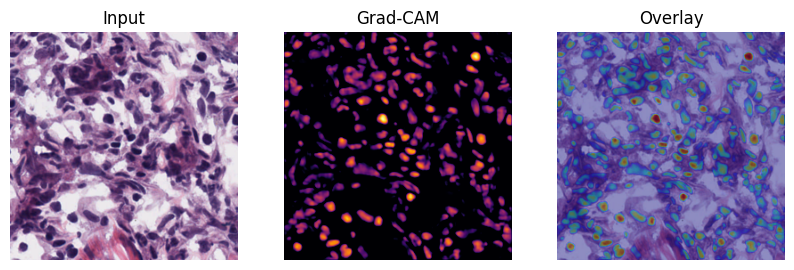

In [ ]:
# ==========================
# 🔥 Segmentation Grad-CAM
# ==========================
import torch
import torch.nn.functional as F
import numpy as np
import cv2
import matplotlib.pyplot as plt

# device (expects `device` variable defined; otherwise infer)
device = "cuda" if torch.cuda.is_available() else "cpu"

# choose a target conv layer (example: first conv in dec1)
# ensures the module exists
try:
    target_layer = model.dec1.seq[0]   # adjust if you want a different layer
except Exception:
    # fallback: pick last conv2d in model
    target_layer = None
    for m in reversed(list(model.modules())):
        if isinstance(m, torch.nn.Conv2d):
            target_layer = m
            break
if target_layer is None:
    raise RuntimeError("No Conv2d layer found in model for Grad-CAM target.")

class SegGradCAM:
    def __init__(self, model, target_layer, device="cpu"):
        self.model = model
        self.target_layer = target_layer
        self.device = device
        self.gradients = None
        self.activations = None

        # forward hook
        self.fwd_hook = target_layer.register_forward_hook(self._save_activation)
        # backward hook (use register_full_backward_hook to avoid deprecation)
        try:
            self.bwd_hook = target_layer.register_full_backward_hook(self._save_gradient)
        except Exception:
            # older torch fallback
            self.bwd_hook = target_layer.register_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        # out: activation tensor
        self.activations = out.detach()

    def _save_gradient(self, module, grad_in, grad_out):
        # grad_out[0] is gradient w.r.t. output
        self.gradients = grad_out[0].detach()

    def generate(self, img_t):
        """
        img_t: torch tensor [1,3,H,W] already on device (normalized as training).
        returns: cam numpy (H,W) normalized [0..1]
        """
        # make sure tensors on right device
        img_t = img_t.to(self.device)

        # zero grads
        self.model.zero_grad()
        self.model.eval()

        # forward
        with torch.enable_grad():
            sam_emb = sam_embedding_from_rgb(img_t)   # use your sam embedding fn
            logits = self.model(img_t, sam_emb)      # (1,1,H,W)
            probs  = torch.sigmoid(logits)

            # Use mean foreground probability as scalar score
            score = probs.mean()

            # backward from score
            score.backward(retain_graph=False)

        # get saved grads & activations
        grads = self.gradients    # (1, C, h, w)
        acts  = self.activations  # (1, C, h, w)
        if grads is None or acts is None:
            raise RuntimeError("Gradients or activations not captured. Ensure generate() is called after a forward+backward pass.")

        # channel weights: global avg pooling of gradients
        weights = grads.mean(dim=(2,3), keepdim=True)   # (1,C,1,1)

        # weighted combination
        cam = (weights * acts).sum(dim=1, keepdim=True)  # (1,1,h,w)
        cam = F.relu(cam)

        # normalize to [0,1]
        cam = cam.squeeze().cpu().numpy()
        cam -= cam.min()
        if cam.max() > 0:
            cam /= (cam.max() + 1e-8)

        # upsample to original image size (256x256 expected)
        cam_up = cv2.resize(cam, (256,256))
        return cam_up

    def close(self):
        # remove hooks
        try:
            self.fwd_hook.remove()
        except Exception:
            pass
        try:
            self.bwd_hook.remove()
        except Exception:
            pass

# ----------------- Usage example -----------------
# assumes `img_t` tensor [1,3,256,256] and `img_disp` PIL.Image (256x256) exist
gradcam = SegGradCAM(model, target_layer, device=device)

# run cam (this will do forward+backward internally)
cam_map = gradcam.generate(img_t)   # numpy HxW in [0,1]

# visualize overlay
img_rgb = np.array(img_disp).astype(np.uint8)
heat = (255 * cam_map).astype(np.uint8)
heat_color = cv2.applyColorMap(heat, cv2.COLORMAP_JET)
overlay = cv2.addWeighted(img_rgb[:, :, ::-1], 0.6, heat_color, 0.4, 0)  # convert RGB->BGR for cv2 ops then back

# show with matplotlib (convert BGR->RGB)
plt.figure(figsize=(10,4))
plt.subplot(1,3,1); plt.imshow(img_rgb); plt.title("Input"); plt.axis("off")
plt.subplot(1,3,2); plt.imshow(cam_map, cmap="inferno"); plt.title("Grad-CAM"); plt.axis("off")
plt.subplot(1,3,3); plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)); plt.title("Overlay"); plt.axis("off")
plt.show()

# cleanup hooks
gradcam.close()


Device: cuda
Loading image: C:\Users\User\Desktop\Btech_purva\human_brain_tissue_8.png
Loading mask: C:\Users\User\Desktop\Btech_purva\human_brain_mask_8.png
Using reference image for Reinhard normalization: C:\Users\User\Desktop\Btech_asmita\unet_project\dataset_zip\images\train\Human_AdrenalGland_01.tif
Applying Reinhard stain normalization to input image...


C:\Users\User\AppData\Local\Temp\ipykernel_18452\1449156060.py:54: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 7 negative Z values that have been clipped to zero
  img_norm = np.clip(lab2rgb(img_norm), 0, 1)


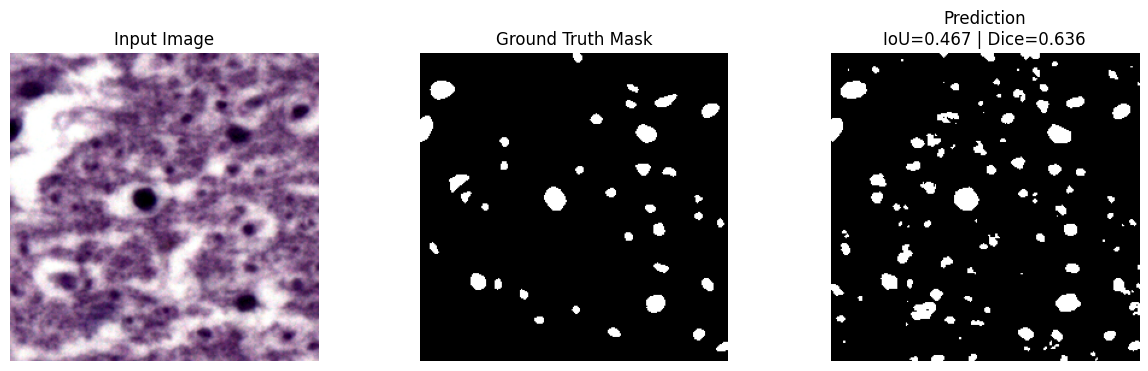


==================== RESULTS ====================
🔥 IoU  : 0.4666
🔥 Dice : 0.6363
Saved predicted binary mask to: C:\Users\User\Desktop\Btech_asmita\unet_project\sam_unet_runs\human_brain_tissue_8_pred_mask.png
Saved probability map (npy) to: C:\Users\User\Desktop\Btech_asmita\unet_project\sam_unet_runs\human_brain_tissue_8_prob_map.npy


In [ ]:
# ============================
# LOCAL INFERENCE + STAIN NORMALIZATION + METRICS
# ============================
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from skimage.color import rgb2lab, lab2rgb
from torchvision import transforms
import torch
import warnings

# ------------------ USER: set local image & mask paths here ------------------
# Replace these with your local image and mask full paths (Windows-style ok)
IMAGE_PATH = r"C:\Users\User\Desktop\Btech_purva\human_brain_tissue_8.png"
MASK_PATH  = r"C:\Users\User\Desktop\Btech_purva\human_brain_mask_8.png"

# Optional: reference image for Reinhard stain normalization (if available).
# If None or not found, normalization is skipped.
REFERENCE_PATH = r"C:\Users\User\Desktop\Btech_asmita\unet_project\dataset_zip\images\train\Human_AdrenalGland_01.tif"

# Output folder
SAVE_DIR = r"C:\Users\User\Desktop\Btech_asmita\unet_project\sam_unet_runs"
os.makedirs(SAVE_DIR, exist_ok=True)

# ------------------ Basic checks ------------------
if not os.path.exists(IMAGE_PATH):
    raise FileNotFoundError(f"Input image not found: {IMAGE_PATH}")
if not os.path.exists(MASK_PATH):
    raise FileNotFoundError(f"Input mask not found: {MASK_PATH}")

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", device)

# ------------------ Preprocessing transform (matches training) ------------------
tf_vis = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# ------------------ Load images ------------------
print("Loading image:", IMAGE_PATH)
img = Image.open(IMAGE_PATH).convert("RGB")
print("Loading mask:", MASK_PATH)
mask = Image.open(MASK_PATH).convert("L")

# ------------------ Reinhard stain normalization (optional) ------------------
def reinhard_normalize(img_np, ref_mean, ref_std):
    img_lab = rgb2lab(img_np)
    img_mean, img_std = img_lab.mean(axis=(0,1)), img_lab.std(axis=(0,1))
    img_norm = (img_lab - img_mean) / (img_std + 1e-8) * (ref_std + 1e-8) + ref_mean
    img_norm = np.clip(lab2rgb(img_norm), 0, 1)
    return (img_norm * 255).astype(np.uint8)

apply_reinhard = False
if REFERENCE_PATH and os.path.exists(REFERENCE_PATH):
    try:
        print("Using reference image for Reinhard normalization:", REFERENCE_PATH)
        ref_img = np.array(Image.open(REFERENCE_PATH).convert("RGB"))
        ref_lab = rgb2lab(ref_img)
        ref_mean, ref_std = ref_lab.mean(axis=(0,1)), ref_lab.std(axis=(0,1))
        apply_reinhard = True
    except Exception as e:
        warnings.warn(f"Reference normalization failed; skipping normalization. Error: {e}")
        apply_reinhard = False
else:
    print("Reference image for Reinhard not found; skipping stain normalization.")

if apply_reinhard:
    try:
        print("Applying Reinhard stain normalization to input image...")
        img_np = np.array(img)
        img_np_norm = reinhard_normalize(img_np, ref_mean, ref_std)
        img = Image.fromarray(img_np_norm)
    except Exception as e:
        warnings.warn(f"Reinhard normalization error — continuing with original image: {e}")

# ------------------ Resize & preprocess ------------------
img_disp = img.resize((256, 256))
img_t = tf_vis(img).unsqueeze(0).to(device)   # [1,3,256,256]
mask_resized = (np.array(mask.resize((256, 256))) > 127).astype(np.float32)

# ------------------ Model inference ------------------
model.eval()
with torch.no_grad(), torch.amp.autocast(device_type="cuda", enabled=(device=="cuda")):
    sam_emb = sam_embedding_from_rgb(img_t)
    logits = model(img_t, sam_emb)            # logits [1,1,256,256] or [1,1,H,W]
    prob_map = torch.sigmoid(logits).squeeze().cpu().numpy()  # HxW

pred_bin = (prob_map > 0.5).astype(np.uint8)

# ------------------ IoU & Dice ------------------
def iou_dice(pred, gt, eps=1e-6):
    pred = (pred > 0.5).astype(np.float32)
    gt = (gt > 0.5).astype(np.float32)
    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum() - inter
    if union == 0:
        return 1.0, 1.0
    iou = (inter + eps) / (union + eps)
    dice = (2 * inter + eps) / (pred.sum() + gt.sum() + eps)
    return float(iou), float(dice)

iou, dice = iou_dice(prob_map, mask_resized)

# ------------------ Visualization ------------------
plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1); plt.imshow(img_disp); plt.title("Input Image"); plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(mask_resized, cmap="gray"); plt.title("Ground Truth Mask"); plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(pred_bin, cmap="gray")
plt.title(f"Prediction\nIoU={iou:.3f} | Dice={dice:.3f}"); plt.axis("off")
plt.show()

print("\n==================== RESULTS ====================")
print(f"🔥 IoU  : {iou:.4f}")
print(f"🔥 Dice : {dice:.4f}")
print("=================================================")

# ------------------ Save outputs ------------------
base_name = os.path.splitext(os.path.basename(IMAGE_PATH))[0]
save_pred_path = os.path.join(SAVE_DIR, f"{base_name}_pred_mask.png")
save_prob_path = os.path.join(SAVE_DIR, f"{base_name}_prob_map.npy")
plt.imsave(save_pred_path, pred_bin, cmap="gray")
np.save(save_prob_path, prob_map)
print("Saved predicted binary mask to:", save_pred_path)
print("Saved probability map (npy) to:", save_prob_path)
